# **📊 Classification Tasks: Customer Churn Prediction**

This file contains the notebook demo for classification utils script example usages.

# **STAGE 0 : BUSINESS UNDERSTANDING**

## 📌 Problem Statement

A telecommunications company is experiencing significant customer attrition (churn), where existing customers discontinue their services and switch to competitors. The current reactive approach—addressing churn only after customers have already left—has proven costly and ineffective. Customer acquisition costs are typically 5-7x higher than retention costs, making each churned customer a substantial financial loss.

The company's customer service team relies on intuition and basic rules to identify at-risk customers, resulting in missed opportunities to intervene before customers leave. Without a data-driven approach, the company cannot effectively prioritize retention efforts or allocate resources efficiently.

Building on this challenge, the company aims to develop a predictive system that can identify customers at high risk of churning before they leave, enabling proactive retention strategies based on historical customer behavior and service usage patterns.

## 📌 Role

As a Data Scientist Team, our role involves:

- Conducting exploratory data analysis to understand customer behavior patterns
- Identifying key factors that contribute to customer churn
- Building predictive models to flag at-risk customers
- Providing actionable insights for business decision-making

## 📌 Goals

- **Proactive Churn Prevention**: Identify at-risk customers before they churn to enable timely intervention. (_MAIN_)
- **Customer Lifetime Value Optimization**: Focus retention efforts on high-value customers most likely to churn. (_SECONDARY_)
- **Resource Allocation Efficiency**: Prioritize marketing and retention budgets toward customers who need it most. (_SECONDARY_)

## 📌 Business Metrics

| Metric                            | Description                                               | Type        |
| --------------------------------- | --------------------------------------------------------- | ----------- |
| **Churn Rate (%)**                | Percentage of customers who churned in a given period     | _MAIN_      |
| **Customer Retention Rate (%)**   | Percentage of customers retained after intervention       | _MAIN_      |
| **Customer Lifetime Value (CLV)** | Projected revenue from a customer over their relationship | _SECONDARY_ |
| **Cost per Acquisition (CPA)**    | Cost to acquire a new customer vs. retain existing        | _SECONDARY_ |

## 📌 Objectives

The ultimate goal of this project is to create a machine learning model that can:

- Predict customer churn with high recall to minimize missed at-risk customers (false negatives are costly)
- Provide probability scores for churn risk to enable tiered intervention strategies
- Identify the top contributing factors to churn for targeted retention campaigns

## 📌 Success Criteria
Note: Dont know this can be achieveable with this dummy data, but we will just see.

- Model achieves **Recall ≥ 80%** for churn class (minimize false negatives)
- Model achieves **Precision ≥ 60%** to avoid excessive false alarms
- Reduction in monthly churn rate by **15-20%** through proactive interventions
- Clear identification of **top 5 churn indicators** for actionable insights

# **STAGE 1 : EXPLORATORY DATA ANALYSIS (EDA)**

## Project Setup

In [1]:
import os
import sys
from pathlib import Path

# # Add root folder to path (for module imports) --> solved to using hatchling in pyproject.toml
# sys.path.insert(0, str(Path.cwd().parent))

# Change working directory (for I/O operations)
os.chdir(Path.cwd().parent)

In [2]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Settings
sns.set_style('darkgrid')
pd.set_option('display.max_columns', None)

## Data Understanding & Initial Transformation

In [3]:
# Read data from local
df_raw = pd.read_csv('data/classification_data.csv')

# # Read data from github
# df_raw = pd.read_csv('https://raw.githubusercontent.com/mcikalmerdeka/ds-dataprep-utils/refs/heads/main/data/classification_data.csv')

# Create a copy of the dataframe
df = df_raw.copy()

In [4]:
# Check the first few rows of the dataset
df.head()

,customer_id,age,gender,tenure_months,monthly_charges,total_charges,contract_type,payment_method,support_tickets,account_balance,internet_service,online_security,satisfaction_score,days_since_last_login,num_products,referral_source,churn,churn_label
0,CUST_00352,52.0,Female,13.0,64.393115,855.8778833905786,Two year,Bank Transfer,1,58.950305,Fiber optic,True,1.6,6.0,1,Friend,1,Yes
1,CUST_00689,46.0,Male,81.0,115.102595,9029.757263810074,Two year,Electronic Check,1,-25.965241,Fiber optic,Yes,4.5,4.0,4,Billboard,0,No
2,CUST_00485,18.0,Other,44.0,74.210796,3123.9632752803795,One year,Credit Card,4,133.015936,DSL,True,3.0,11.0,4,Email,0,No
3,CUST_00388,54.0,Male,9.0,20.353377,179.8634663715755,One year,Bank Transfer,4,-13.197764,No,Yes,2.6,11.0,1,Google,1,Yes
4,CUST_00031,67.0,Female,0.0,90.937098,0.0,One year,Electronic Check,4,-95.459565,DSL,yes,3.3,63.0,1,Facebook,1,Yes


In [5]:
# Checking shape of dataframe
print(f'Number of rows: {df.shape[0]}')
print(f'Number of columns {df.shape[1]}')

Number of rows: 1050
Number of columns 18


In [6]:
# Check data information
from utils import check_data_information

info_df = check_data_information(df, df.columns.tolist())
display(info_df)

,Feature,Data Type,Null Values,Null Percentage,Zero Values,Zero Percentage,Negative Values,Negative Percentage,Empty Strings,Numeric in Object,Duplicated Values,Unique Values,Cardinality Ratio,Unique Sample
0,customer_id,object,0,0.00,0,0.00,0,0.00,0,0,50,1000,0.9524,"CUST_00352, CUST_00689, CUST_00485, CUST_00388..."
1,age,float64,80,7.62,0,0.00,9,0.86,0,0,50,80,0.0762,"52.0, 46.0, 18.0, 54.0, 67.0"
2,gender,object,0,0.00,0,0.00,0,0.00,0,0,50,5,0.0048,"Female, Male, Other, FEMALE, male"
3,tenure_months,float64,99,9.43,91,8.67,0,0.00,0,0,50,95,0.0905,"13.0, 81.0, 44.0, 9.0, 0.0"
4,monthly_charges,float64,91,8.67,0,0.00,37,3.52,0,0,50,913,0.8695,"64.39311525514046, 115.10259485286996, 74.2107..."
5,total_charges,object,105,10.00,0,0.00,0,0.00,35,891,50,780,0.7429,"855.8778833905786, 9029.757263810074, 3123.963..."
6,contract_type,object,7,0.67,0,0.00,0,0.00,0,0,50,4,0.0038,"Two year, One year, Month-to-month, monthly, nan"
7,payment_method,object,66,6.29,0,0.00,0,0.00,22,0,50,5,0.0048,"Bank Transfer, Electronic Check, Credit Card, ..."
8,support_tickets,int64,0,0.00,144,13.71,0,0.00,0,0,50,8,0.0076,"1, 4, 2, 0, 3"
9,account_balance,float64,0,0.00,0,0.00,527,50.19,0,0,50,1000,0.9524,"58.9503049877248, -25.965240829469444, 133.015..."


In [7]:
# Count total of null values
print(f"Total null values: {df.isnull().sum().sum()}")

Total null values: 648


Feature Information:

| Feature                 | Description                           | Type        | **Specific Data Type** |
| ----------------------- | ------------------------------------- | ----------- | ---------------------- |
| `customer_id`           | Unique customer identifier            | ID          | Nominal                 |
| `age`                   | Customer age                          | Numeric     | Continuous             |
| `gender`                | Customer gender                       | Categorical | Nominal                |
| `tenure_months`         | Months as a customer                  | Numeric     | Discrete               |
| `monthly_charges`       | Monthly billing amount                | Numeric     | Continuous             |
| `total_charges`         | Cumulative charges                    | Numeric     | Continuous             |
| `contract_type`         | Service contract type                 | Categorical | Ordinal                |
| `payment_method`        | Payment method used                   | Categorical | Nominal                |
| `support_tickets`       | Number of support requests            | Numeric     | Discrete               |
| `account_balance`       | Current account balance               | Numeric     | Continuous             |
| `internet_service`      | Type of internet service              | Categorical | Nominal                |
| `online_security`       | Has online security add-on            | Categorical | Nominal                |
| `satisfaction_score`    | Customer satisfaction (1-5)           | Numeric     | Continuous             |
| `days_since_last_login` | Engagement metric                     | Numeric     | Continuous             |
| `num_products`          | Number of products subscribed         | Numeric     | Discrete               |
| `referral_source`       | How customer was acquired             | Categorical | Nominal                |
| **`churn`**             | **Target: Did customer churn? (0/1)** | **Binary**  | Nominal                |

In [8]:
# Group columns by data type
nums_cols = df.select_dtypes(include=['int64', 'float64']).columns.to_list()
cats_cols = df.select_dtypes(include=['object', 'category']).columns.to_list()

target = "churn"
target_label = "churn_label"

In [9]:
# Checking unique values for each categorical columns (for more detail value checking)
for col in cats_cols:
    print()
    unique_vals = df[col].unique()
    if len(unique_vals) > 30:
        print(f"{col}: {unique_vals[:30]} ...")
    else:
        print(f"{col}: {unique_vals}")


customer_id: ['CUST_00352' 'CUST_00689' 'CUST_00485' 'CUST_00388' 'CUST_00031'
 'CUST_00442' 'CUST_00198' 'CUST_00425' 'CUST_00107' 'CUST_00714'
 'CUST_00552' 'CUST_00675' 'CUST_00158' 'CUST_00475' 'CUST_00423'
 'CUST_00656' 'CUST_00617' 'CUST_00483' 'CUST_00884' 'CUST_00650'
 'CUST_00244' 'CUST_00847' 'CUST_00982' 'CUST_00828' 'CUST_00570'
 'CUST_00059' 'CUST_00290' 'CUST_00070' 'CUST_00344' 'CUST_00184'] ...

gender: ['Female' 'Male' 'Other' 'FEMALE' 'male']

total_charges: ['855.8778833905786' '9029.757263810074' '3123.9632752803795'
 '179.8634663715755' '0.0' '3223.3497479774633' '1178.5549395078542'
 '2054.244446922844' nan '649.5617830274659' '1291.6164073707732'
 '169.1788022058472' '1337.695036052829' '835.5272703553898'
 '2700.8463502325053' '9403.674371660214' ' ' '119.86955114435887'
 '1375.0597102996771' '2003.99443775134' '2097.5031921945288'
 '396.26647735650374' '530.6408821814283' '1017.7103432895155'
 '293.05464496323356' '56.321902446339074' '273.5551480649047'
 '799

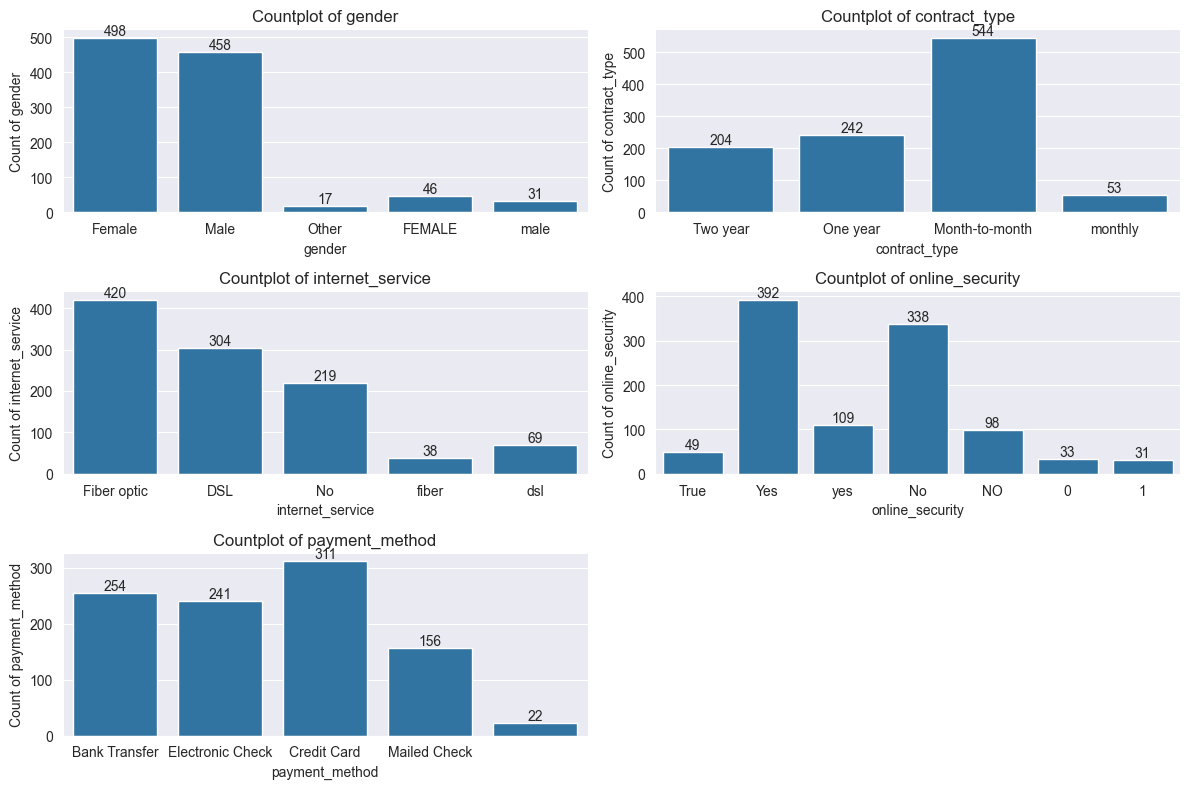

In [10]:
# Quick check on the categorical distribution for problematic columns
columns_to_check = ["gender", "contract_type", "internet_service", "online_security", "payment_method"]

# Using the utils function
from utils import plot_dynamic_countplot
plot_dynamic_countplot(df, columns_to_check, ncols=2, figsize=(12, 8))

In [11]:
# Initial preprocessing of normalizing categorical values

## Handle gender column values
df["gender"] = df["gender"].replace({"FEMALE": "Female", "male": "Male", "Other": "Male"})

## Handle internet_service column values
df["internet_service"] = df["internet_service"].replace({"fiber": "Fiber Optic", "Fiber optic": "Fiber Optic", "dsl": "DSL"})

## Handle contract_type column values
df["contract_type"] = df["contract_type"].replace({"Month-to-month": "Monthly", "monthly": "Monthly", "one_year": "Yearly", "two_year": "Yearly"})

## Handle online_Security column values
df["online_security"] = df["online_security"].replace(
    {"True": "Yes", "yes": "Yes", "NO": "No", "no": "No", "0": "No", "1": "Yes"})

## Handle empyty string values in payment_method column
df["payment_method"] = df["payment_method"].replace({" ": "Credit Card"})

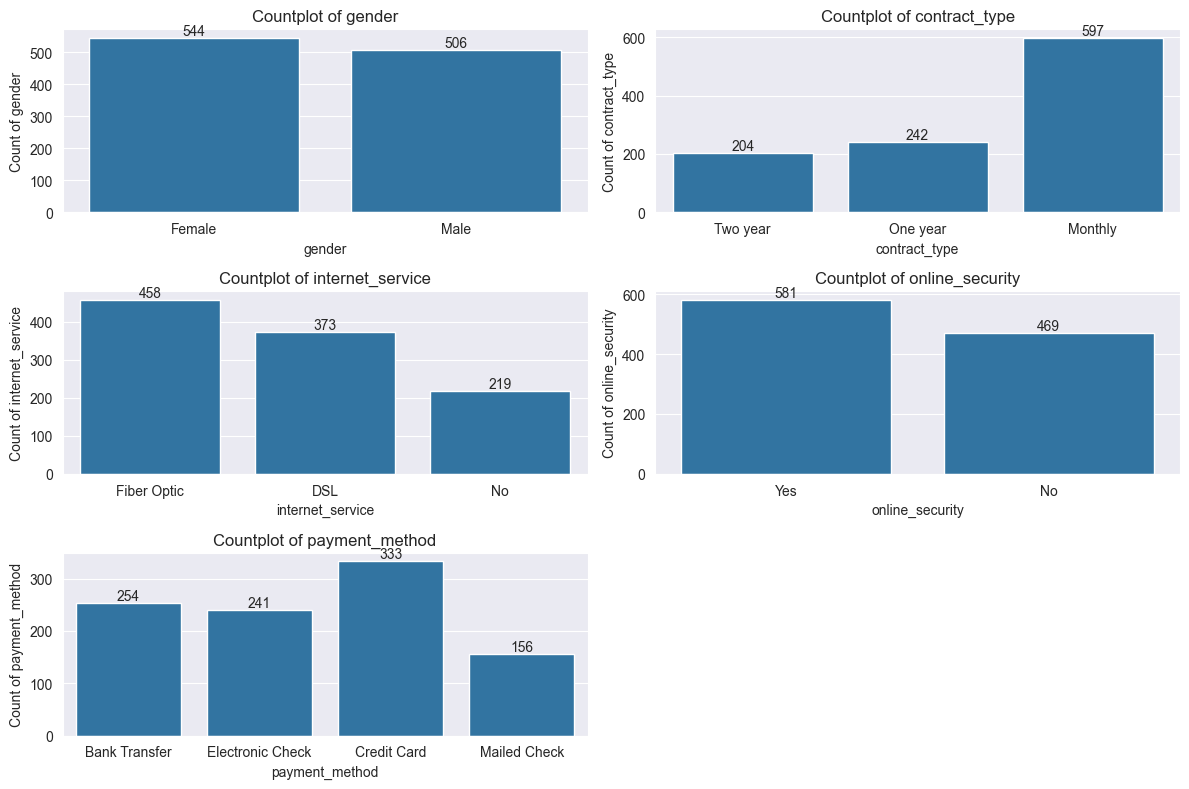

In [12]:
# Re-check after transformation
plot_dynamic_countplot(df, columns_to_check, ncols=2, figsize=(12, 8))

In [13]:
# Initial data preprocessing of string values in an numerical column

## First, let's identify the types of values in total_charges
print("Unique value types in total_charges:")
print(df["total_charges"].value_counts())
print(f"\nData type: {df['total_charges'].dtype}")

## Check for non-numeric values
def is_numeric(val):
    try:
        float(val)
        return True
    except (ValueError, TypeError):
        return False

non_numeric_mask = ~df["total_charges"].apply(is_numeric)
print(f"\nNumber of non-numeric values: {non_numeric_mask.sum()}")
print("\nNon-numeric values found:")
print(df.loc[non_numeric_mask, "total_charges"].value_counts())

## Handle the non-numeric values
# Replace empty strings and whitespace with NaN
df["total_charges"] = df["total_charges"].replace(r'^\s*$', np.nan, regex=True)

# Replace 'Pending' or similar text values with NaN
df["total_charges"] = df["total_charges"].replace(['Pending', 'pending', 'PENDING'], np.nan)

# Convert to numeric, coercing errors to NaN
df["total_charges"] = pd.to_numeric(df["total_charges"], errors='coerce')

print(f"\nAfter conversion:")
print(f"Data type: {df['total_charges'].dtype}")
print(f"Null values: {df['total_charges'].isnull().sum()}")
print(f"Valid numeric values: {df['total_charges'].notna().sum()}")

# Ensure total_charges is treated as numeric for analysis
nums_cols = df.select_dtypes(include=['int64', 'float64']).columns.to_list()
if 'total_charges' in df.columns and 'total_charges' not in nums_cols:
    nums_cols.append('total_charges')

cats_cols = df.select_dtypes(include=['object', 'category']).columns.to_list()
if 'total_charges' in cats_cols:
    cats_cols.remove('total_charges')

Unique value types in total_charges:
total_charges
0.0                   76
                      19
Pending               19
                      16
693.6204866570193      2
                      ..
147.63658790689672     1
1191.0371604943653     1
126.84723256866658     1
1582.824397863934      1
6511.9168552485635     1
Name: count, Length: 780, dtype: int64

Data type: object

Number of non-numeric values: 54

Non-numeric values found:
total_charges
           19
Pending    19
           16
Name: count, dtype: int64

After conversion:
Data type: float64
Null values: 159
Valid numeric values: 891


In [14]:
# Initial data preprocessing of drop duplicates and null values
from utils import handle_missing_values 

## Drop duplicated values
df = df.drop_duplicates()

## Drop null values
null_cols = df.columns[df.isnull().any()].tolist()
df, _ = handle_missing_values(
    data=df,
    strategy="remove",
    columns=null_cols,
)

In [15]:
# Check the dataset shape after initial cleaning
print(f'Dataset shape after initial cleaning: {df.shape}')
print(f'\nTarget distribution:')
print(df['churn'].value_counts(normalize=True))

Dataset shape after initial cleaning: (513, 18)

Target distribution:
churn
0    0.594542
1    0.405458
Name: proportion, dtype: float64


In [16]:
# Check data information after initial preprocessing
from utils import check_data_information

info_df = check_data_information(df, df.columns.tolist())
display(info_df)

,Feature,Data Type,Null Values,Null Percentage,Zero Values,Zero Percentage,Negative Values,Negative Percentage,Empty Strings,Numeric in Object,Duplicated Values,Unique Values,Cardinality Ratio,Unique Sample
0,customer_id,object,0,0.0,0,0.00,0,0.00,0,0,0,513,1.0000,"CUST_00352, CUST_00689, CUST_00485, CUST_00388..."
1,age,float64,0,0.0,0,0.00,4,0.78,0,0,0,70,0.1365,"52.0, 46.0, 18.0, 54.0, 67.0"
2,gender,object,0,0.0,0,0.00,0,0.00,0,0,0,2,0.0039,"Female, Male"
3,tenure_months,float64,0,0.0,45,8.77,0,0.00,0,0,0,82,0.1598,"13.0, 81.0, 44.0, 9.0, 0.0"
4,monthly_charges,float64,0,0.0,0,0.00,20,3.90,0,0,0,513,1.0000,"64.39311525514046, 115.10259485286996, 74.2107..."
5,total_charges,float64,0,0.0,45,8.77,5,0.97,0,0,0,469,0.9142,"855.8778833905786, 9029.757263810074, 3123.963..."
6,contract_type,object,0,0.0,0,0.00,0,0.00,0,0,0,3,0.0058,"Two year, One year, Monthly"
7,payment_method,object,0,0.0,0,0.00,0,0.00,0,0,0,4,0.0078,"Bank Transfer, Electronic Check, Credit Card, ..."
8,support_tickets,int64,0,0.0,68,13.26,0,0.00,0,0,0,8,0.0156,"1, 4, 0, 3, 2"
9,account_balance,float64,0,0.0,0,0.00,254,49.51,0,0,0,513,1.0000,"58.9503049877248, -25.965240829469444, 133.015..."


## Univariate Analysis

**Purpose:** Understand distributions and basic statistics of features before splitting.

### Numerical Features

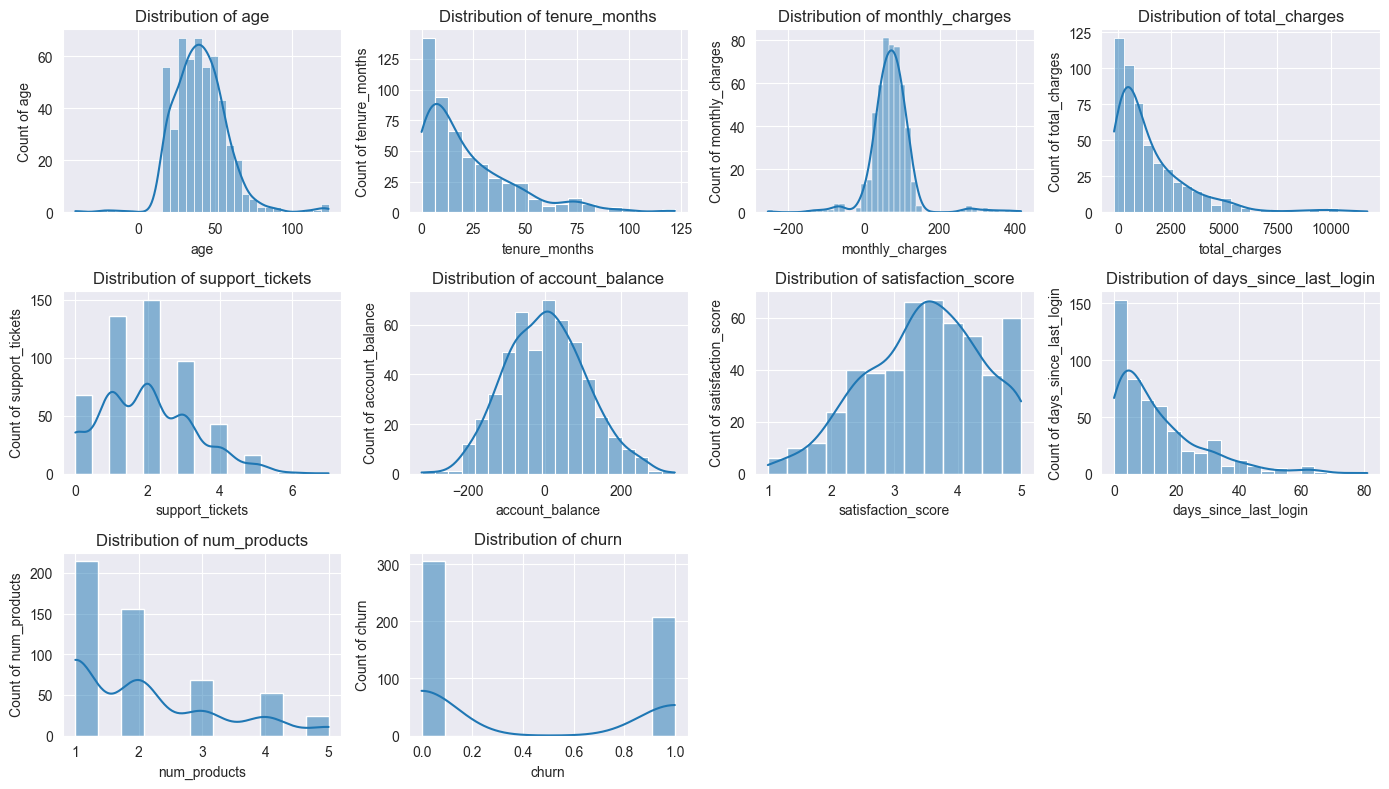

,Feature,overall_count,overall_mean,overall_std,overall_min,overall_25%,overall_50%,overall_75%,overall_max,overall_range,overall_IQR,overall_CV,overall_skewness,overall_kurtosis
0,age,513.0,40.377198,17.267566,-41.092743,29.000000,40.000000,50.000000,123.694732,164.787475,21.000000,42.765638,0.725719,4.325863
1,tenure_months,513.0,21.968811,22.437130,0.000000,6.000000,14.000000,32.000000,122.000000,122.000000,26.000000,102.131746,1.559877,2.534883
2,monthly_charges,513.0,72.753499,58.343311,-253.108889,48.111926,71.567755,95.259511,414.634142,667.743031,47.147585,80.193134,1.265036,11.059446
3,total_charges,513.0,1551.739608,1877.835854,-181.485933,308.282229,873.397674,2142.744758,11731.806760,11913.292694,1834.462529,121.014882,2.318865,6.890340
4,support_tickets,513.0,1.945419,1.308380,0.000000,1.000000,2.000000,3.000000,7.000000,7.000000,2.000000,67.254415,0.514646,0.041830
5,account_balance,513.0,3.628012,104.245319,-321.605720,-68.813706,1.318026,72.127813,339.812732,661.418452,140.941519,2873.345113,0.163430,-0.111730
6,satisfaction_score,513.0,3.489084,0.917664,1.000000,2.800000,3.500000,4.100000,5.000000,4.000000,1.300000,26.301001,-0.288938,-0.471549
7,days_since_last_login,513.0,14.216374,14.479847,0.000000,3.000000,9.000000,21.000000,81.000000,81.000000,18.000000,101.853308,1.648785,2.978027
8,num_products,513.0,2.058480,1.172808,1.000000,1.000000,2.000000,3.000000,5.000000,4.000000,2.000000,56.974503,0.962680,-0.044095
9,churn,513.0,0.405458,0.491460,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,121.210978,0.385115,-1.851687


In [17]:
# Checking the distribution and statistical summary of the numerical values
from utils import plot_dynamic_hisplots_kdeplots, describe_numerical_combined
plot_dynamic_hisplots_kdeplots(df=df, col_series=nums_cols, ncols=4, figsize=(14, 8))

# Display the overall statistics for numerical columns
numerical_summary = describe_numerical_combined(df, nums_cols)
display(numerical_summary)

### Categorical Features

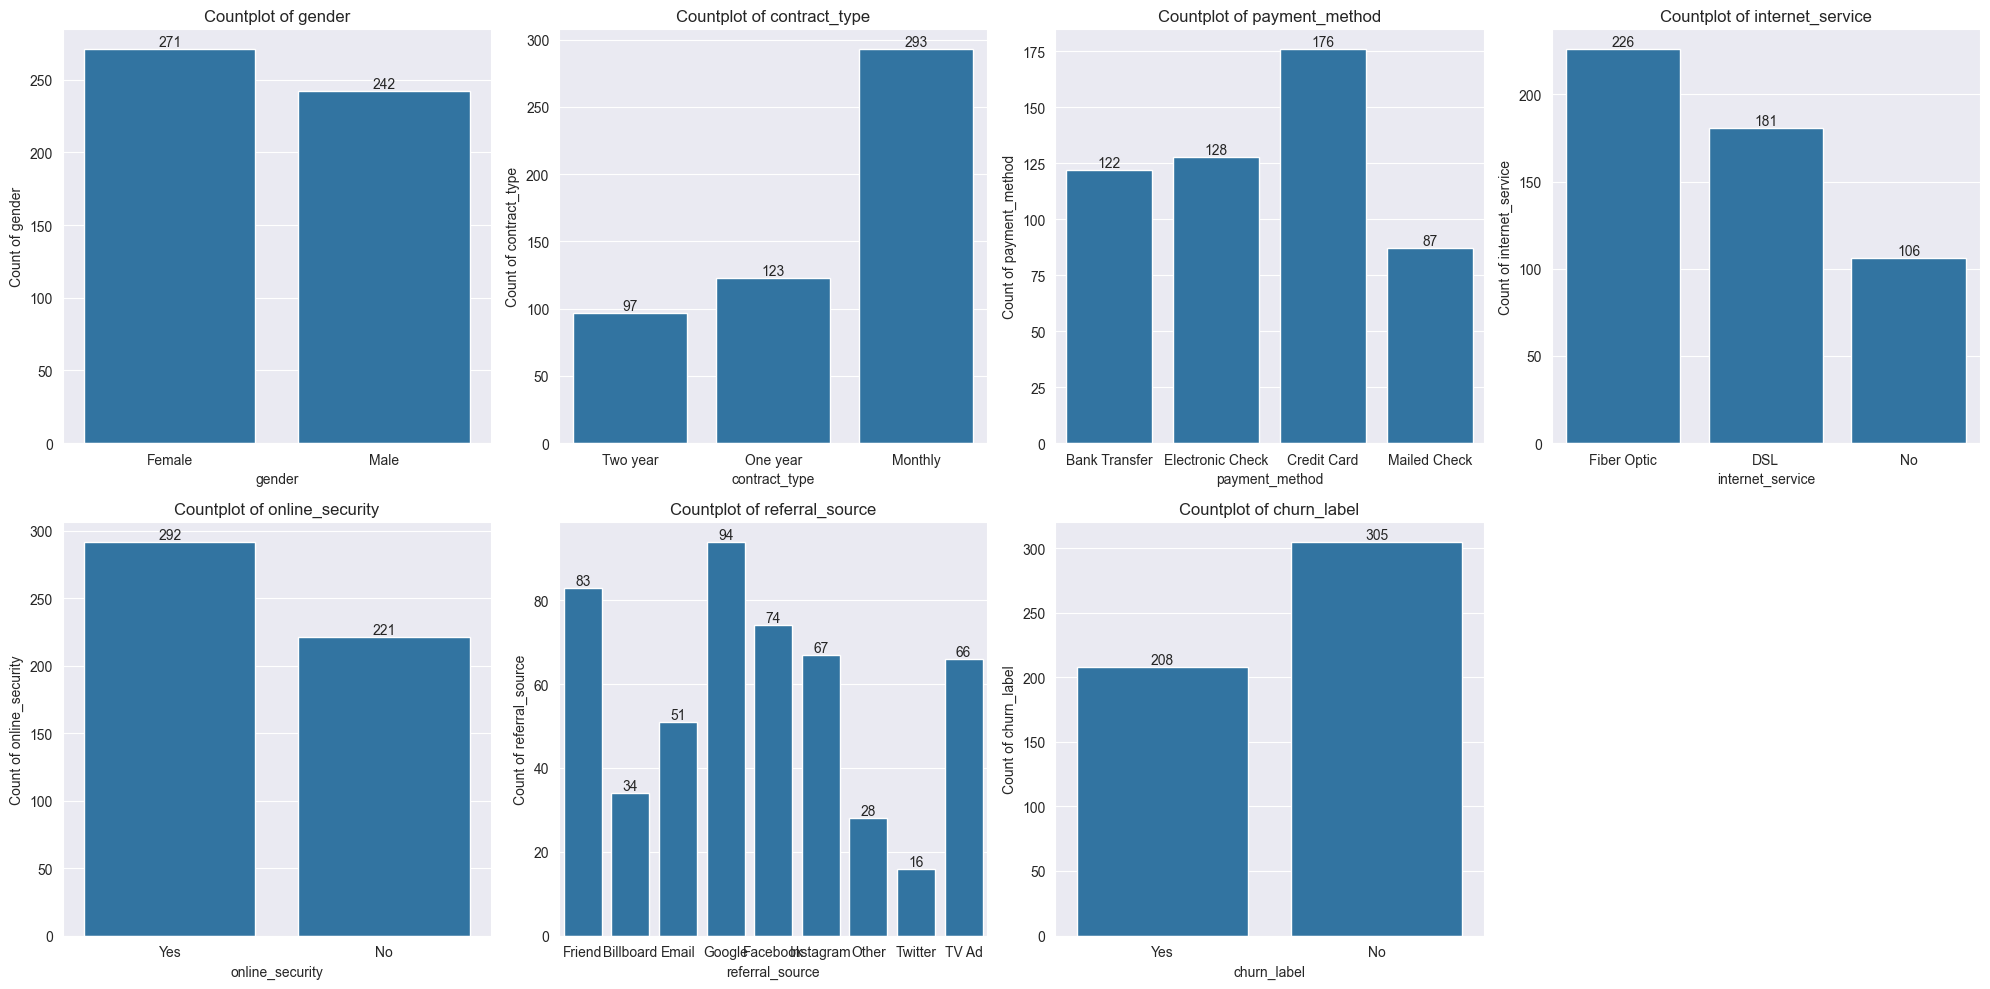

,Feature,overall_count,overall_unique,overall_top,overall_freq,overall_bottom,overall_freq_bottom,overall_top_percentage,overall_bottom_percentage,overall_n_categories
0,customer_id,513,513,CUST_00352,1,CUST_00352,1,0.19,0.19,513
1,gender,513,2,Female,271,Male,242,52.83,47.17,2
2,contract_type,513,3,Monthly,293,Two year,97,57.12,18.91,3
3,payment_method,513,4,Credit Card,176,Mailed Check,87,34.31,16.96,4
4,internet_service,513,3,Fiber Optic,226,No,106,44.05,20.66,3
5,online_security,513,2,Yes,292,No,221,56.92,43.08,2
6,referral_source,513,9,Google,94,Twitter,16,18.32,3.12,9
7,churn_label,513,2,No,305,Yes,208,59.45,40.55,2


In [18]:
# Checking the distribution and statistical summary of the categorical values
from utils import describe_categorical_combined, plot_dynamic_countplot

# Countplot function implementation
plot_dynamic_countplot(df=df, col_series=[col for col in cats_cols if col != "customer_id"], ncols=4, figsize=(20, 10))

# Display the overall statistics for categorical columns
categorical_summary = describe_categorical_combined(df, cats_cols)
display(categorical_summary)


Chi-Square Analysis Results:
--------------------------------------------------------------------------------


,Feature,Chi-Square,P-Value,Cramér's V,Effect Size,Is Significant,Strongest Category,Association Direction
5,referral_source,6.031361,0.643719,0.108430,Small,False,Facebook,Positive
2,payment_method,2.576678,0.461593,0.070871,Negligible,False,Mailed Check,Positive
3,internet_service,2.173186,0.337364,0.065086,Negligible,False,DSL,Positive
0,gender,1.025202,0.311288,0.044704,Negligible,False,Male,Negative
4,online_security,0.499980,0.479509,0.031219,Negligible,False,No,Positive
1,contract_type,0.203293,0.903349,0.019907,Negligible,False,One year,Positive


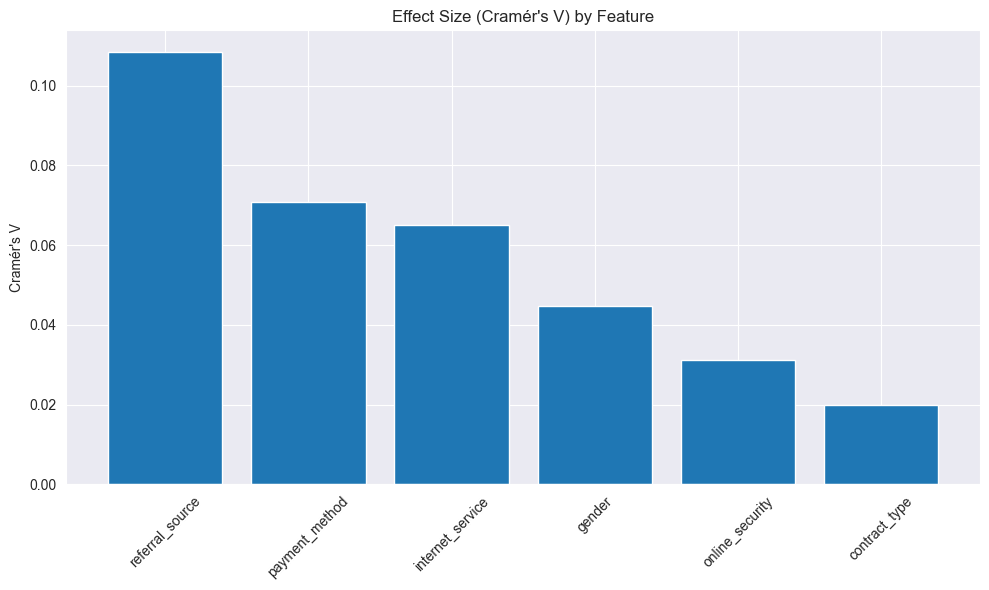

In [19]:
# Categorical features correlation analysis
from utils import analyze_categorical_relationships

# Analyze relationships between categorical features and target
results = analyze_categorical_relationships(
    df, 
    features=[col for col in cats_cols if col not in ["customer_id", "churn_label"]], 
    target=target_label, 
    alpha=0.05
)

## Bivariate/Multivariate Analysis

<Figure size 1500x1500 with 0 Axes>

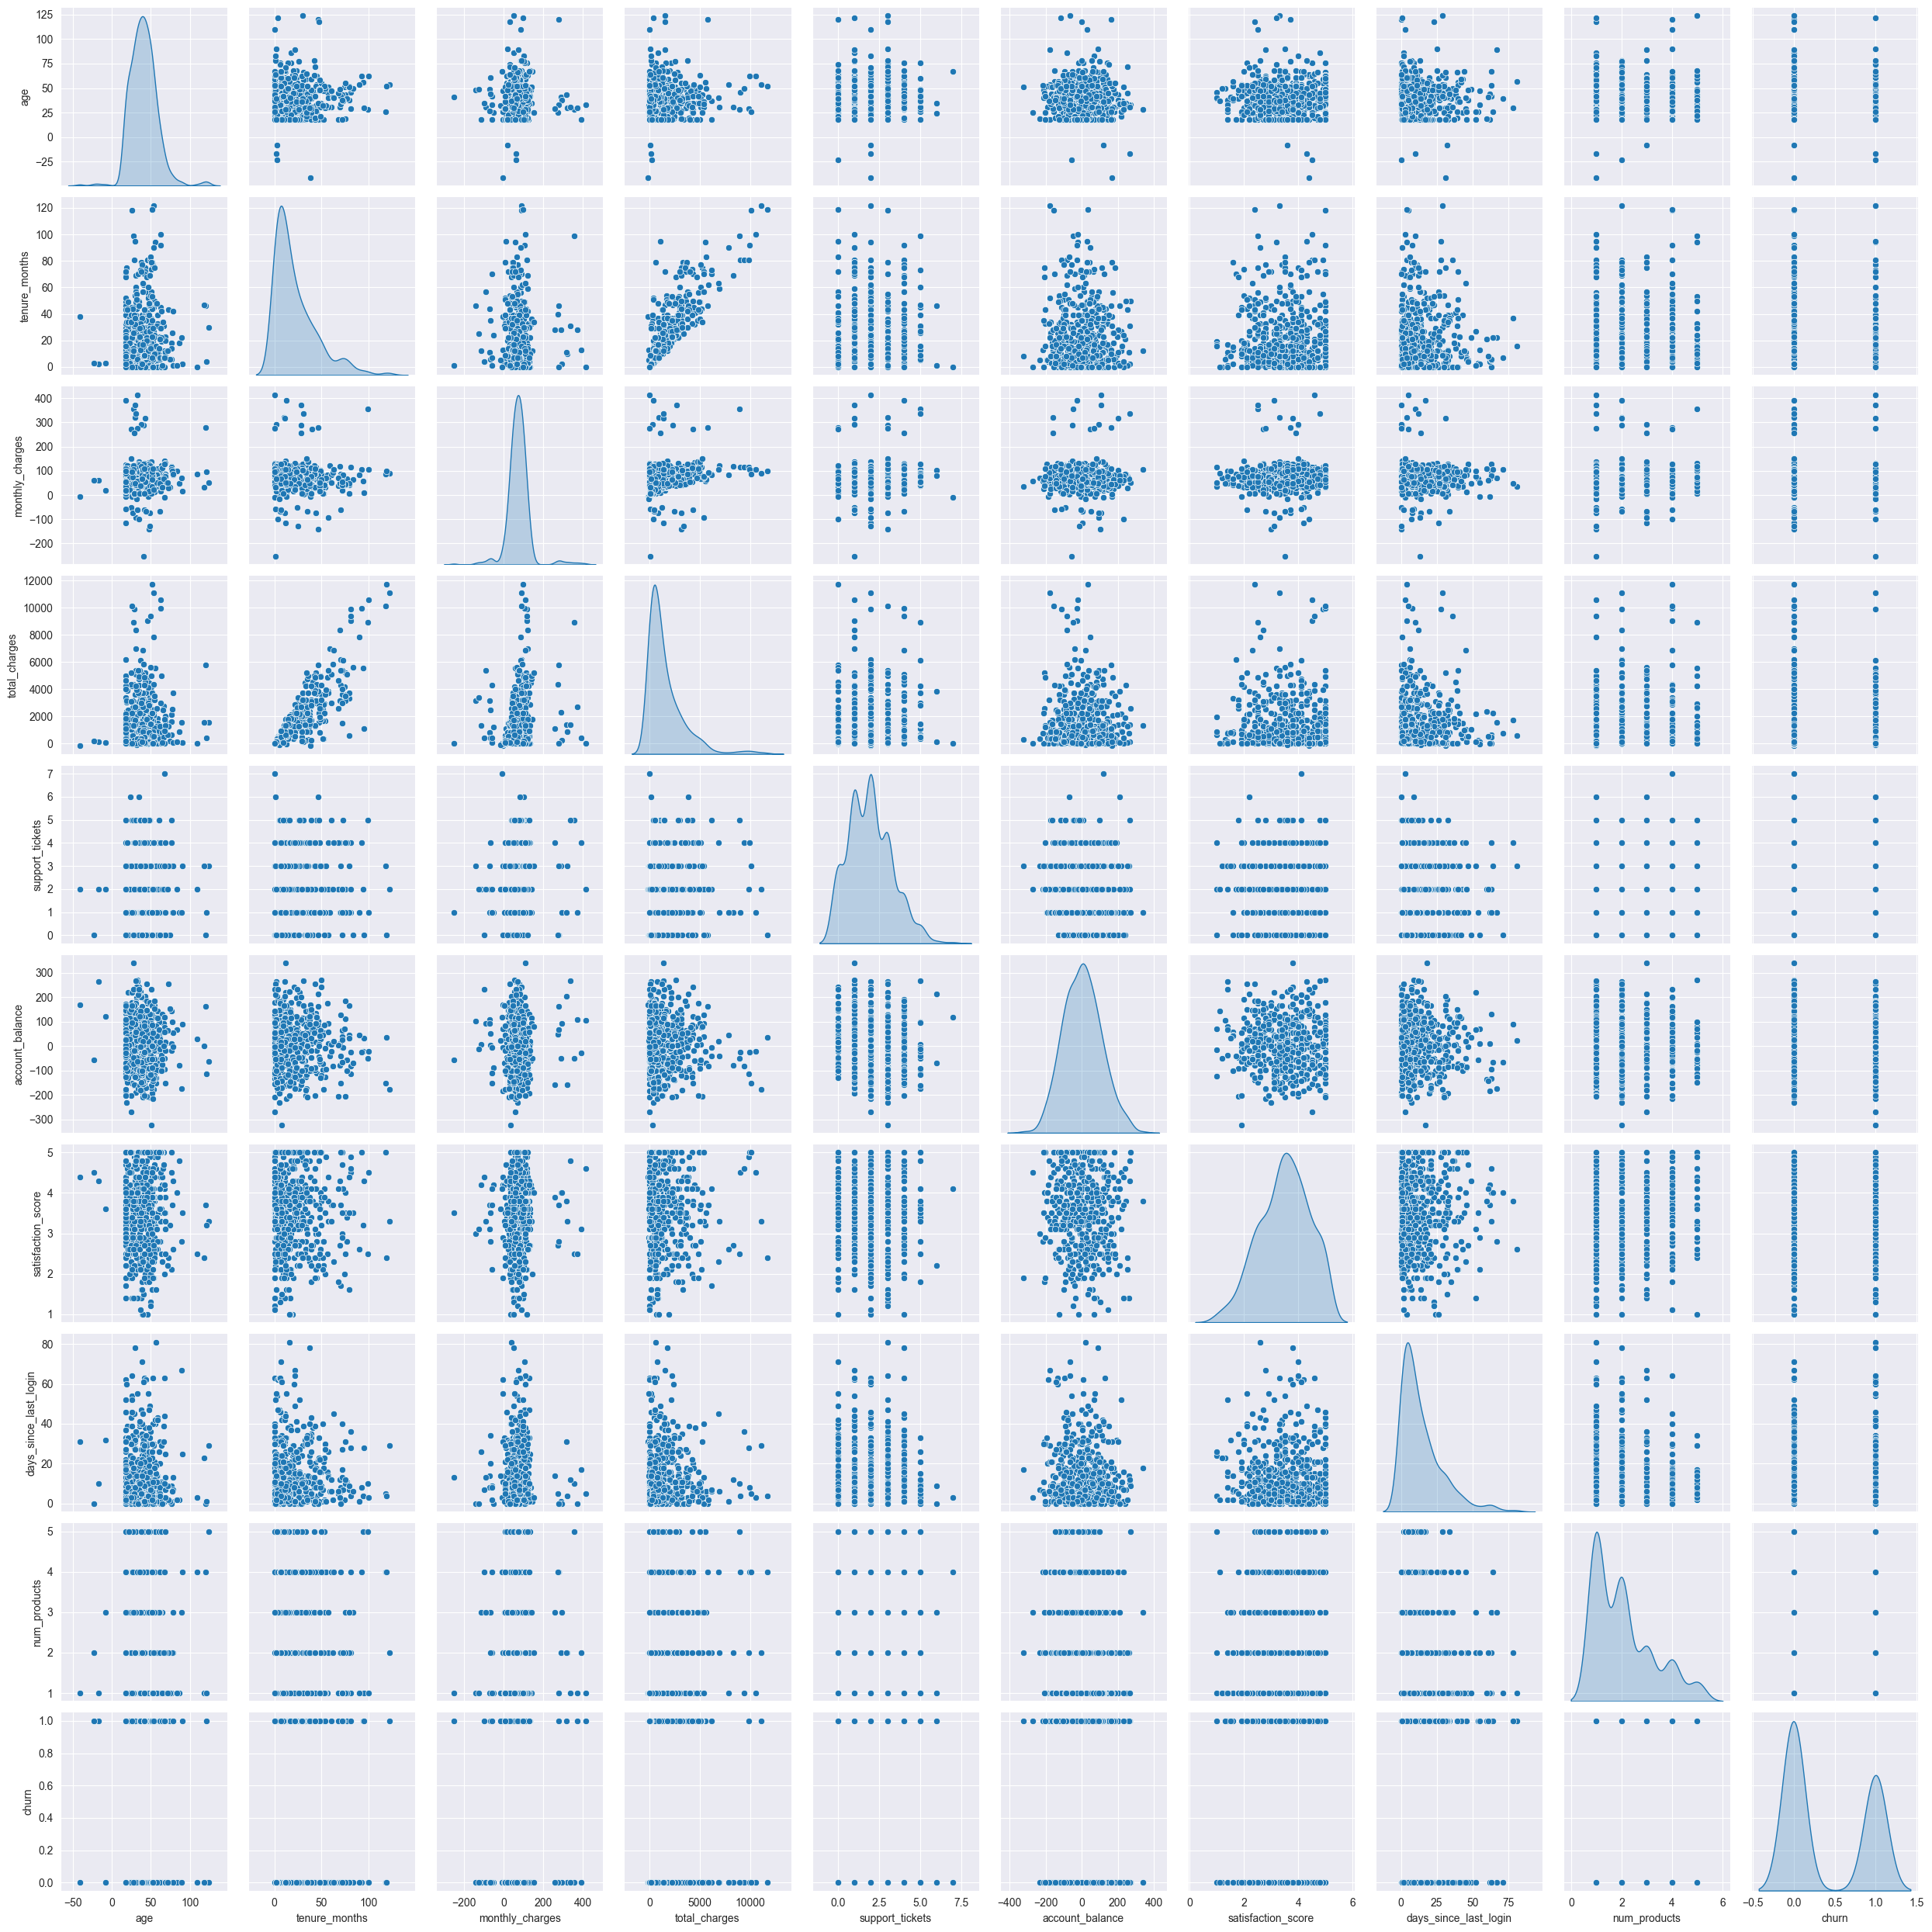

In [20]:
# Checking pairplot
plt.figure(figsize=(15, 15))
sns.pairplot(data=df, diag_kind='kde')
plt.tight_layout()
plt.show()

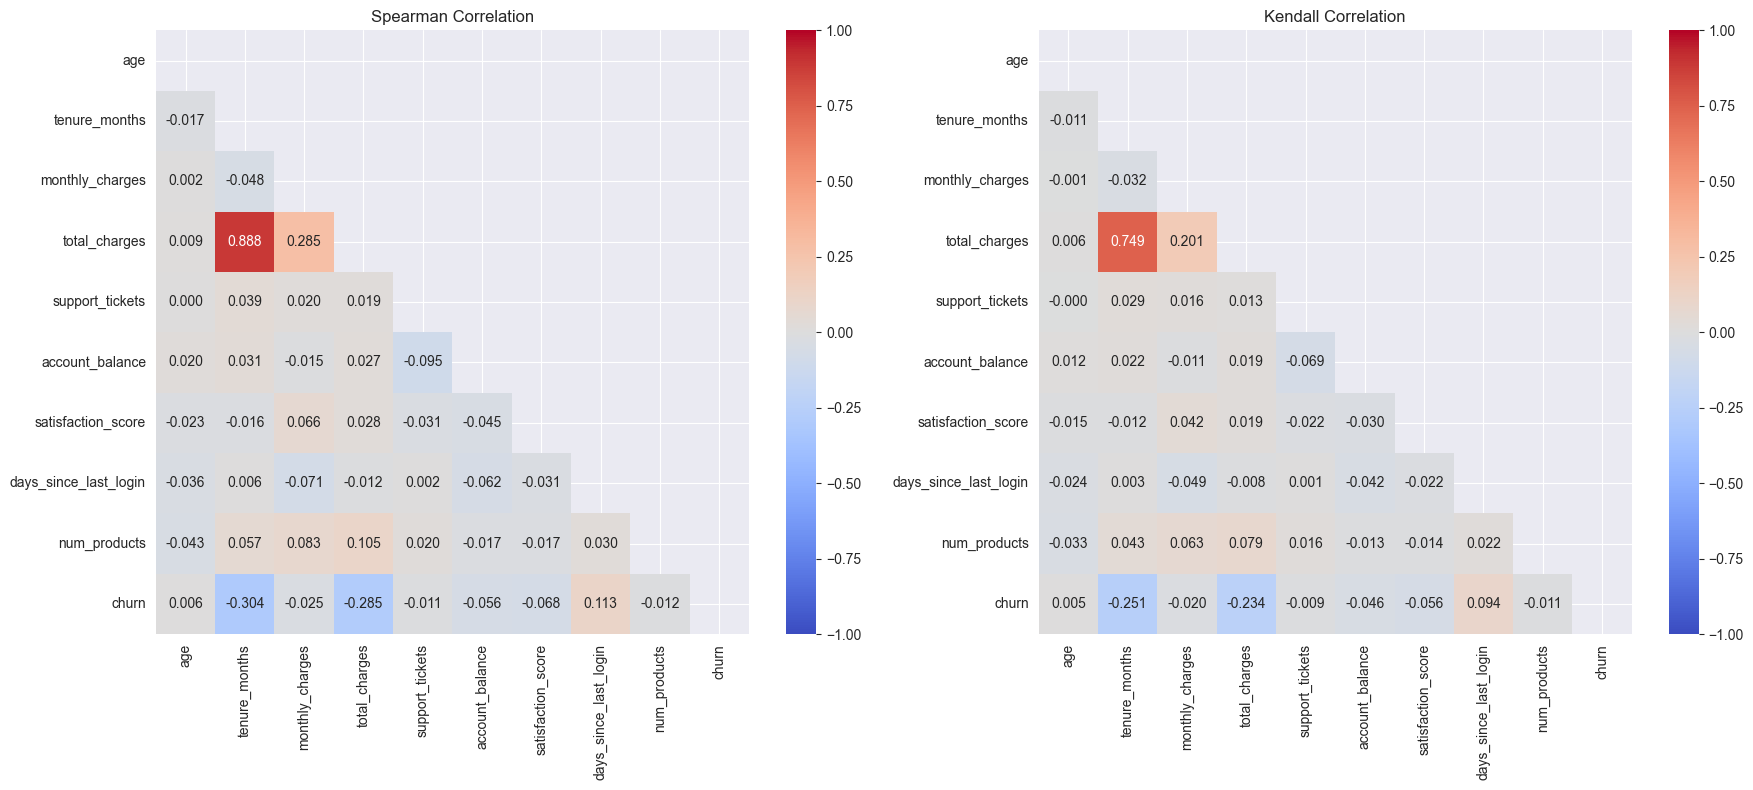

In [21]:
# Correlation heatmap of numerical features and target
fig, ax = plt.subplots(1, 2, figsize=(18, 8))

# Create a mask for the upper triangle
mask = np.triu(np.ones_like(df.corr(numeric_only=True), dtype=bool))

# Plot correlation heatmap with Spearman method
sns.heatmap(data=df.corr(method='spearman', numeric_only=True), mask=mask, cmap='coolwarm', annot=True, fmt='.3f', vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title('Spearman Correlation')

# Plot correlation heatmap with Kendall method
sns.heatmap(data=df.corr(method='kendall', numeric_only=True), mask=mask, cmap='coolwarm', annot=True, fmt='.3f', vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title('Kendall Correlation')

plt.tight_layout()
plt.show()

# **STAGE 2: DATA SPLITTING (CRITICAL STEP)**

**Splitting BEFORE preprocessing prevents data leakage:**

1. **Outlier Removal:** If we calculate IQR on full dataset, test set statistics influence training decisions
2. **Feature Encoding:** Category frequencies from test set shouldn't inform training
3. **Feature Selection:** Correlation/importance scores using test data = cheating
4. **Scaling:** Already doing this correctly, but must come after split

**Principle:** Test set should be completely unseen until final evaluation. It should simulate future data where we don't know the answers.

## Split Strategy: 75% Train, 20% Validation, 5% Test

- **Training (75%):** Fit all preprocessing steps and train models
- **Validation (20%):** Tune hyperparameters and select best model
- **Test (5%):** Final evaluation only, never touched during development

**Note:** For classification, we stratify by the target variable (`churn`) to ensure representative distribution of both classes across all splits.

In [22]:
from sklearn.model_selection import train_test_split

# Drop customer_id and churn_label (redundant with churn target)
cols_to_drop = ['customer_id', 'churn_label']

# Separate features and target
X_raw = df.drop(columns=[target] + cols_to_drop)
y_raw = df[target]

# First split: 75% train, 25% temp (which will become val + test)
X_train_raw, X_temp_raw, y_train_raw, y_temp_raw = train_test_split(
    X_raw, y_raw, 
    test_size=0.25, 
    random_state=42,
    stratify=y_raw  # Stratify by target for classification
)

# Second split: Split temp into 80% validation (20% of original) and 20% test (5% of original)
X_val_raw, X_test_raw, y_val_raw, y_test_raw = train_test_split(
    X_temp_raw, y_temp_raw, 
    test_size=0.2, 
    random_state=42,
    stratify=y_temp_raw  # Stratify by target for classification
)

# Display split sizes
total_samples = len(X_raw)
print(f"Total samples: {total_samples:,}")
print(f"\nTraining set: {len(X_train_raw):,} samples ({len(X_train_raw)/total_samples*100:.1f}%)")
print(f"Validation set: {len(X_val_raw):,} samples ({len(X_val_raw)/total_samples*100:.1f}%)")
print(f"Test set: {len(X_test_raw):,} samples ({len(X_test_raw)/total_samples*100:.1f}%)")

# Check target distribution across splits
print(f"\nTarget distribution in Training set:")
print(y_train_raw.value_counts(normalize=True))
print(f"\nTarget distribution in Validation set:")
print(y_val_raw.value_counts(normalize=True))
print(f"\nTarget distribution in Test set:")
print(y_test_raw.value_counts(normalize=True))

Total samples: 513

Training set: 384 samples (74.9%)
Validation set: 103 samples (20.1%)
Test set: 26 samples (5.1%)

Target distribution in Training set:
churn
0    0.59375
1    0.40625
Name: proportion, dtype: float64

Target distribution in Validation set:
churn
0    0.592233
1    0.407767
Name: proportion, dtype: float64

Target distribution in Test set:
churn
0    0.615385
1    0.384615
Name: proportion, dtype: float64


# **STAGE 3: DATA PREPROCESSING (TRAIN + VAL ONLY)**

From this point forward:
- All preprocessing is **fitted on training data only**
- Validation and test sets are **transformed** using training statistics
- We never look at test set until final evaluation

## Outlier Detection and Removal

**Why after split?** IQR thresholds calculated from training data only. If we used full dataset, test set extreme values would influence what we consider "outliers" in training.

Amount of Rows: 384
Amount of Outlier Rows (Across All Columns): 83
Amount of Non-Outlier Rows (Across All Columns): 301
Percentage of Outliers: 21.61%



,Column Name,Outlier Exist,Lower Limit,Upper Limit,Outlier Data,Non-Outlier Data,Outlier Percentage (%)
0,age,True,0.000000,80.000000,9,375,2.34
1,tenure_months,True,-33.000000,71.000000,19,365,4.95
2,monthly_charges,True,-28.511143,166.933071,20,364,5.21
3,total_charges,True,-2420.618781,4817.073249,26,358,6.77
4,support_tickets,True,-2.000000,6.000000,1,383,0.26
5,account_balance,True,-289.590669,287.857525,2,382,0.52
6,satisfaction_score,False,0.812500,6.112500,0,384,0.00
7,days_since_last_login,True,-22.875000,46.125000,20,364,5.21
8,num_products,False,-2.000000,6.000000,0,384,0.00


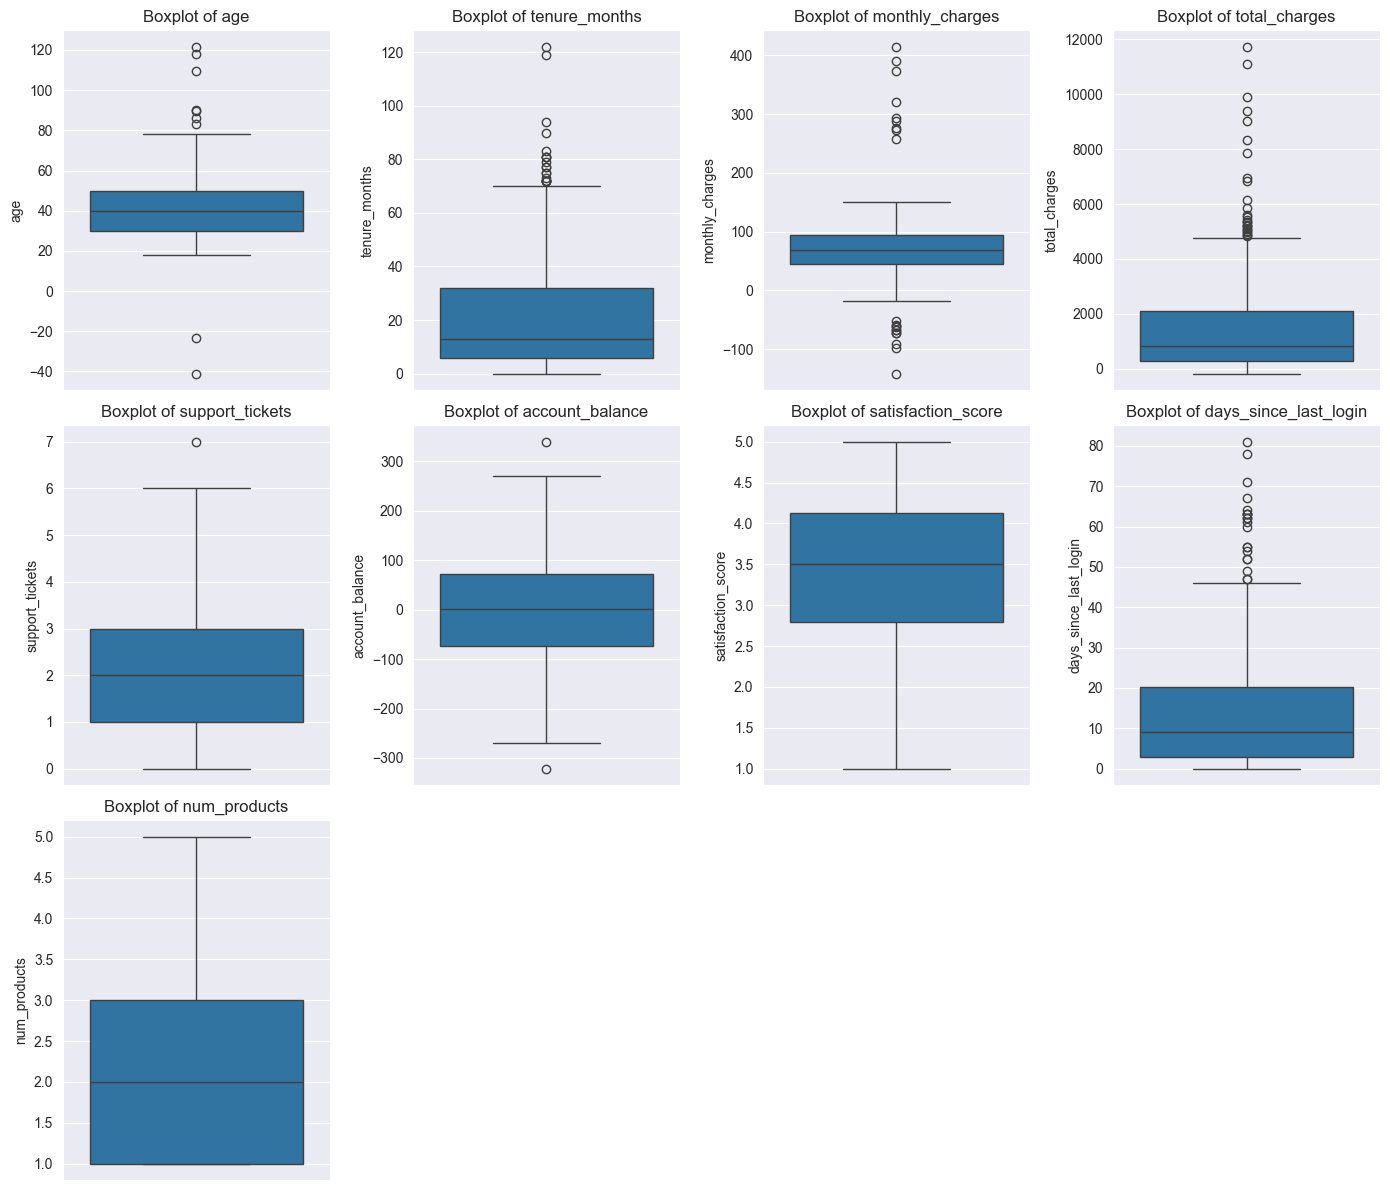

In [23]:
from utils import filter_outliers, plot_dynamic_boxplots_violinplots

# Combine train features and target for outlier detection
df_train = pd.concat([X_train_raw, y_train_raw], axis=1)

# Check outliers on TRAINING data only
summary = filter_outliers(df_train, columns=[col for col in nums_cols if col != "churn"], threshold=1.5, detect_only=True)
display(summary)

# Visualize outliers in training data
plot_dynamic_boxplots_violinplots(df_train, [col for col in nums_cols if col != "churn"], plot_type="boxplot", ncols=4, orientation="v", figsize=(14, 12))

In [24]:
# Remove outliers from TRAINING data and get IQR limits
# These limits will be applied to validation data to ensure consistent distributions
# (This prevents data leakage by using only training statistics)

# Step 1: Get IQR limits from training data
train_outlier_summary = filter_outliers(df_train, columns=[col for col in nums_cols if col != "churn"], method='iqr', threshold=1.5, detect_only=True, verbose=False)

# Step 2: Remove outliers from training data
df_train_clean = filter_outliers(df_train, columns=[col for col in nums_cols if col != "churn"], method='iqr', threshold=1.5, detect_only=False)
X_train_clean = df_train_clean.drop(columns=[target])
y_train_clean = df_train_clean[target]

# Step 3: Apply SAME IQR limits to validation data
# This ensures validation set has the same distribution as training, preventing the mismatch issue
def filter_using_training_limits(data, columns, limits_df):
    """
    Filter outliers using pre-computed IQR limits from training data.
    This prevents data leakage while ensuring consistent distributions.
    """
    mask = pd.Series([True] * len(data), index=data.index)
    
    for _, row in limits_df.iterrows():
        col = row['Column Name']
        if col in columns and col in data.columns:
            lower = row['Lower Limit']
            upper = row['Upper Limit']
            col_mask = (data[col] >= lower) & (data[col] <= upper)
            mask = mask & col_mask
    
    return data[mask]

# Combine validation features and target for filtering
df_val = pd.concat([X_val_raw, y_val_raw], axis=1)
df_val_clean = filter_using_training_limits(df_val, [col for col in nums_cols if col != "churn"], train_outlier_summary)

# Split back into X and y
X_val_clean = df_val_clean.drop(columns=[target])
y_val_clean = df_val_clean[target]

print(f"Training samples after outlier removal: {len(X_train_clean):,}")
print(f"Removed {len(X_train_raw) - len(X_train_clean):,} outlier samples from training set")
print(f"\nValidation samples after applying training limits: {len(X_val_clean):,}")
print(f"Removed {len(X_val_raw) - len(X_val_clean):,} outlier samples from validation set")
print(f"\nTest set: {len(X_test_raw):,} (unchanged - for final evaluation only)")

Training samples after outlier removal: 301
Removed 83 outlier samples from training set

Validation samples after applying training limits: 91
Removed 12 outlier samples from validation set

Test set: 26 (unchanged - for final evaluation only)


## Feature Encoding

**Why after split?** 
- Ordinal encoding order is a modeling decision
- One-hot encoding creates categories based on unique values - test set categories shouldn't influence this
- We fit encoders on training data, then apply to val/test

**Encoding Strategy:**
- **Binary Encoding**: For binary features (gender, online_security, etc.)
- **Ordinal Encoding**: For ordered categories (contract_type)
- **One-Hot Encoding**: For nominal categories with low cardinality (internet_service, payment_method, referral_source)

In [25]:
from utils import feature_encoding

# Define encoding strategy
ordinal_cols = ["contract_type"]
ordinal_categories = {
    "contract_type": ["Monthly", "One year", "Two year"]  # Ordered by commitment length
}

nominal_cols = ["internet_service", "payment_method", "referral_source"]

# Binary columns - will be handled with label encoding before feature_encoding
# We use simple label encoding: Male=1, Female=0, Yes=1, No=0
binary_cols = ["gender", "online_security"]
binary_map = {"Male": 1, "Female": 0, "Yes": 1, "No": 0}

# Label encode binary columns on all sets before feature encoding
for col in binary_cols:
    if col in X_train_clean.columns:
        X_train_clean[col] = X_train_clean[col].map(binary_map)
    if col in X_val_clean.columns:
        X_val_clean[col] = X_val_clean[col].map(binary_map)
    if col in X_test_raw.columns:
        X_test_raw[col] = X_test_raw[col].map(binary_map)

# FIT encoders on TRAINING data only
X_train_encoded, encoders = feature_encoding(
    data=X_train_clean.copy(),
    ordinal_columns=ordinal_cols,
    nominal_columns=nominal_cols,
    ordinal_categories=ordinal_categories,
    handle_unknown='ignore'
)

# Encode validation data - TRANSFORM using fitted encoders
X_val_encoded, _ = feature_encoding(
    data=X_val_clean.copy(),
    ordinal_columns=ordinal_cols,
    nominal_columns=nominal_cols,
    ordinal_categories=ordinal_categories,
    encoders=encoders,
    handle_unknown='ignore'
)

# Encode test data - TRANSFORM using fitted encoders
X_test_encoded, _ = feature_encoding(
    data=X_test_raw.copy(),
    ordinal_columns=ordinal_cols,
    nominal_columns=nominal_cols,
    ordinal_categories=ordinal_categories,
    encoders=encoders,
    handle_unknown='ignore'
)

print(f"Encoded features shape: {X_train_encoded.shape}")
print(f"\nFeature columns after encoding:")
print(X_train_encoded.columns.tolist())

Encoded features shape: (301, 25)

Feature columns after encoding:
['contract_type', 'internet_service_Fiber Optic', 'internet_service_No', 'payment_method_Credit Card', 'payment_method_Electronic Check', 'payment_method_Mailed Check', 'referral_source_Email', 'referral_source_Facebook', 'referral_source_Friend', 'referral_source_Google', 'referral_source_Instagram', 'referral_source_Other', 'referral_source_TV Ad', 'referral_source_Twitter', 'age', 'gender', 'tenure_months', 'monthly_charges', 'total_charges', 'support_tickets', 'account_balance', 'online_security', 'satisfaction_score', 'days_since_last_login', 'num_products']


## Feature Selection

**Why after split?** 
- Correlation analysis using test data = data leakage
- Feature importance scores should only reflect training data patterns
- Selected features must be based on train set only

In [26]:
from utils import calculate_correlation_tabular

# Combine train data for correlation analysis
df_train_encoded = pd.concat([X_train_encoded, y_train_clean.reset_index(drop=True)], axis=1)

# Calculate correlation on TRAINING data only
feature_feature_df, feature_target_df = calculate_correlation_tabular(
    df_train_encoded, 
    target_col=target, 
    method='spearman', 
    corr_type='both'
)

Correlation Between Features:


,A,B,Corr Value,Corr Type
0,total_charges,tenure_months,0.861439,Positive
1,internet_service_Fiber Optic,internet_service_No,0.477915,Negative
2,payment_method_Credit Card,payment_method_Electronic Check,0.408822,Negative
3,payment_method_Credit Card,payment_method_Mailed Check,0.339385,Negative
4,total_charges,monthly_charges,0.302944,Positive
5,payment_method_Mailed Check,payment_method_Electronic Check,0.251562,Negative
6,referral_source_Google,referral_source_Friend,0.228260,Negative
7,referral_source_TV Ad,referral_source_Google,0.207016,Negative
8,referral_source_TV Ad,referral_source_Friend,0.193820,Negative
9,referral_source_Google,referral_source_Facebook,0.190502,Negative



Correlation of Features to Target:


,Feature,Corr Value,Corr Type
0,payment_method_Mailed Check,0.306427,Negative
1,referral_source_Twitter,0.171068,Negative
2,satisfaction_score,0.165557,Positive
3,payment_method_Credit Card,0.152033,Positive
4,online_security,0.131565,Positive
5,referral_source_TV Ad,0.127318,Positive
6,days_since_last_login,0.118532,Positive
7,support_tickets,0.099523,Negative
8,contract_type,0.098957,Negative
9,referral_source_Other,0.086937,Positive


In [27]:
from utils import calculate_feature_importance

# Calculate feature importance using TRAINING data only
feature_importance_f = calculate_feature_importance(
    X=X_train_encoded, 
    y=y_train_clean.reset_index(drop=True), 
    task='classification', 
    method='anova', 
    k='all'
)

print("Feature importance (F-classif, top 15):")
display(feature_importance_f.iloc[:15].reset_index(drop=True))

Feature importance (F-classif, top 15):


,Feature,Score,P_Values
0,tenure_months,31.447236,4.664406e-08
1,total_charges,24.554196,1.211525e-06
2,referral_source_Google,3.012393,8.366045e-02
3,referral_source_Friend,2.019692,1.563127e-01
4,days_since_last_login,1.727506,1.897371e-01
5,satisfaction_score,1.438977,2.312547e-01
6,gender,0.949651,3.305959e-01
7,internet_service_Fiber Optic,0.860353,3.543880e-01
8,monthly_charges,0.446852,5.043495e-01
9,payment_method_Mailed Check,0.402238,5.264208e-01


In [28]:
# Calculate mutual information on TRAINING data only
feature_importance_mi = calculate_feature_importance(
    X=X_train_encoded, 
    y=y_train_clean.reset_index(drop=True), 
    task='classification', 
    method='mutual_info', 
    k='all'
)

print("Feature importance (Mutual Info, top 15):")
display(feature_importance_mi.iloc[:15].reset_index(drop=True))

Feature importance (Mutual Info, top 15):


,Feature,Score,P_Values
0,age,0.100475,None
1,num_products,0.067322,None
2,internet_service_Fiber Optic,0.063364,None
3,total_charges,0.052363,None
4,account_balance,0.048579,None
5,tenure_months,0.044736,None
6,days_since_last_login,0.020134,None
7,internet_service_No,0.012682,None
8,support_tickets,0.012273,None
9,referral_source_Friend,0.002272,None


In [29]:
# Select features based on training data analysis 
# Note: to simplify this we will just use all of the features, we write them like this just in case there is something to remove
base_cols = ["age", "gender", "tenure_months", "monthly_charges",
       "support_tickets", "account_balance", "online_security", "satisfaction_score",
       "days_since_last_login", "num_products", "contract_type"]
       
internet_service_cols = [col for col in X_train_encoded.columns if col.startswith("internet_service_")]
payment_method_cols = [col for col in X_train_encoded.columns if col.startswith("payment_method_")]
referral_source_cols = [col for col in X_train_encoded.columns if col.startswith("referral_source_")]

selected_cols = base_cols + internet_service_cols + payment_method_cols + referral_source_cols

# Apply feature selection to all sets
X_train_selected = X_train_encoded[selected_cols]
X_val_selected = X_val_encoded[selected_cols]
X_test_selected = X_test_encoded[selected_cols]

print(f"Selected {len(selected_cols)} features for modeling")
print(f"\nTraining set: {X_train_selected.shape}")
print(f"Validation set: {X_val_selected.shape}")
print(f"Test set: {X_test_selected.shape}")

Selected 24 features for modeling

Training set: (301, 24)
Validation set: (91, 24)
Test set: (26, 24)


## Feature Scaling

**Why after split?** Scaler parameters (mean, std) calculated from training data only.

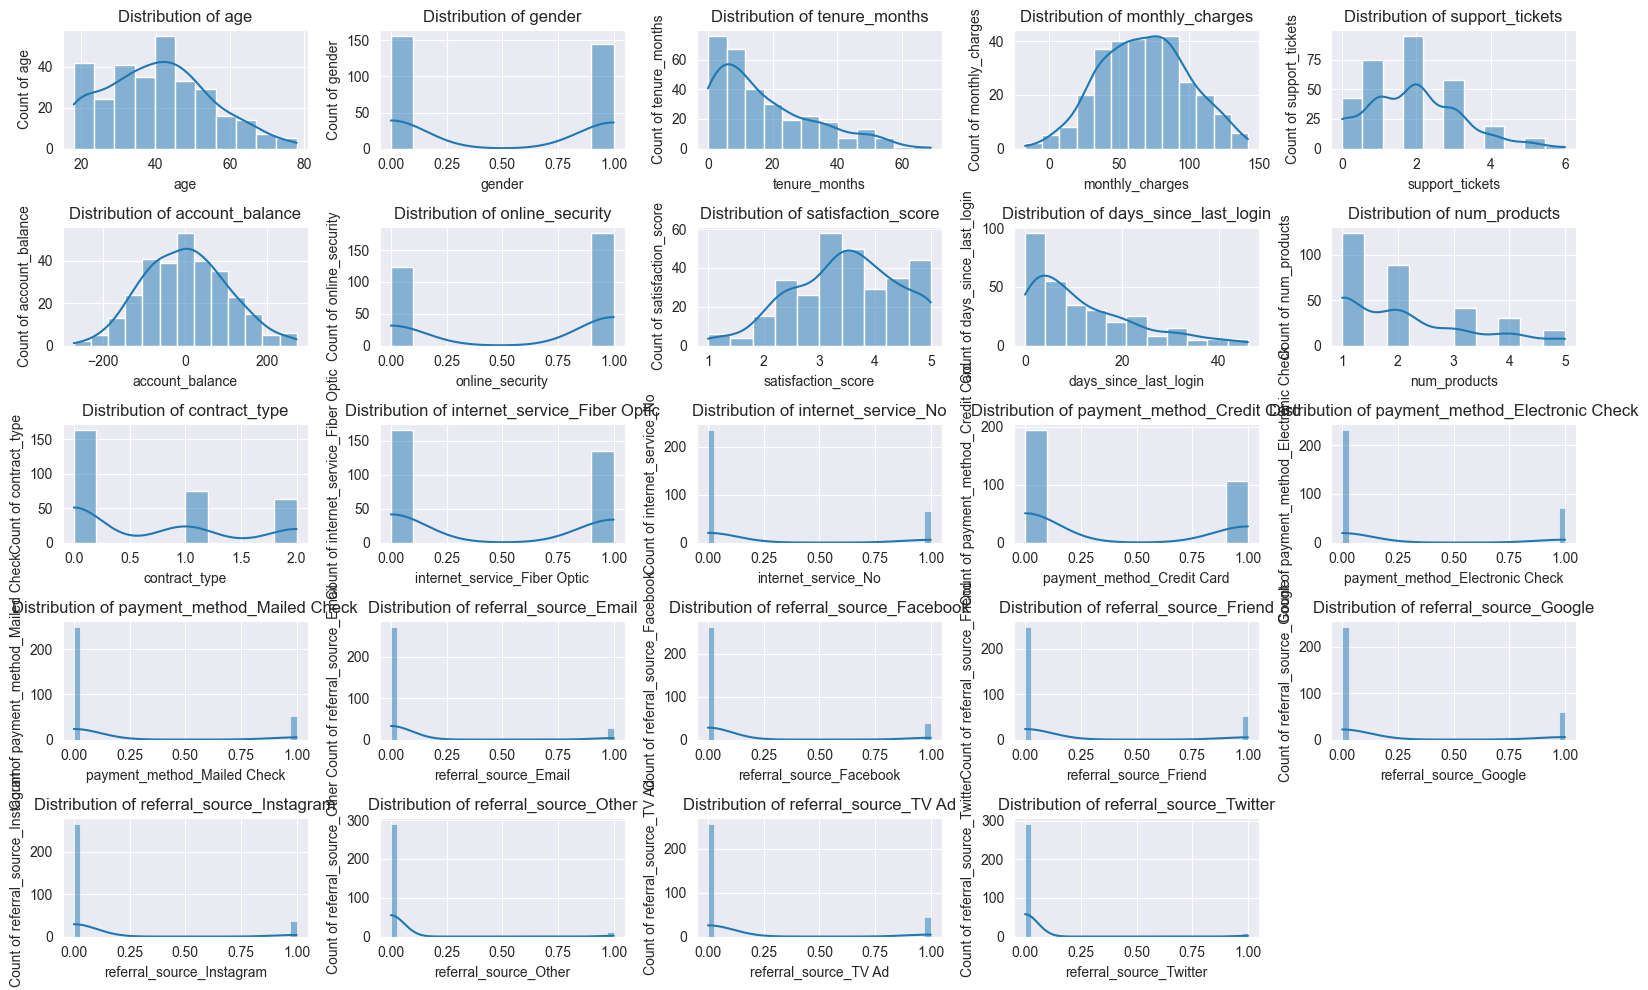

In [30]:
# Check distribution before scaling
plot_dynamic_hisplots_kdeplots(df=X_train_selected, col_series=selected_cols, ncols=5, figsize=(16, 10))

In [31]:
from utils import feature_scaling

# Define scaling configuration
scaling_config = {
    "minmax": {
        # Bounded ranges, relatively uniform or known-range distributions
        "columns": ["age", "tenure_months", "satisfaction_score", "num_products", "support_tickets"]
    },
    "standard": {
        # Normal-ish or skewed distributions with potential outliers
        "columns": ["account_balance", "monthly_charges", "days_since_last_login"]
    }
}

# FIT scaler on TRAINING data only
X_train_scaled, scaler = feature_scaling(
    data=X_train_selected.copy(),
    scaling_config=scaling_config
)

# TRANSFORM validation data using fitted scaler
X_val_scaled, _ = feature_scaling(
    data=X_val_selected.copy(),
    scaling_config=scaling_config,
    scaler=scaler
)

# TRANSFORM test data using fitted scaler
X_test_scaled, _ = feature_scaling(
    data=X_test_selected.copy(),
    scaling_config=scaling_config,
    scaler=scaler
)

print(f"Training set: {X_train_scaled.shape[0]} samples ({X_train_scaled.shape[0]/total_samples*100:.1f}%)")
print(f"Validation set: {X_val_scaled.shape[0]} samples ({X_val_scaled.shape[0]/total_samples*100:.1f}%)")
print(f"Test set: {X_test_scaled.shape[0]} samples ({X_test_scaled.shape[0]/total_samples*100:.1f}%)")

Training set: 301 samples (58.7%)
Validation set: 91 samples (17.7%)
Test set: 26 samples (5.1%)


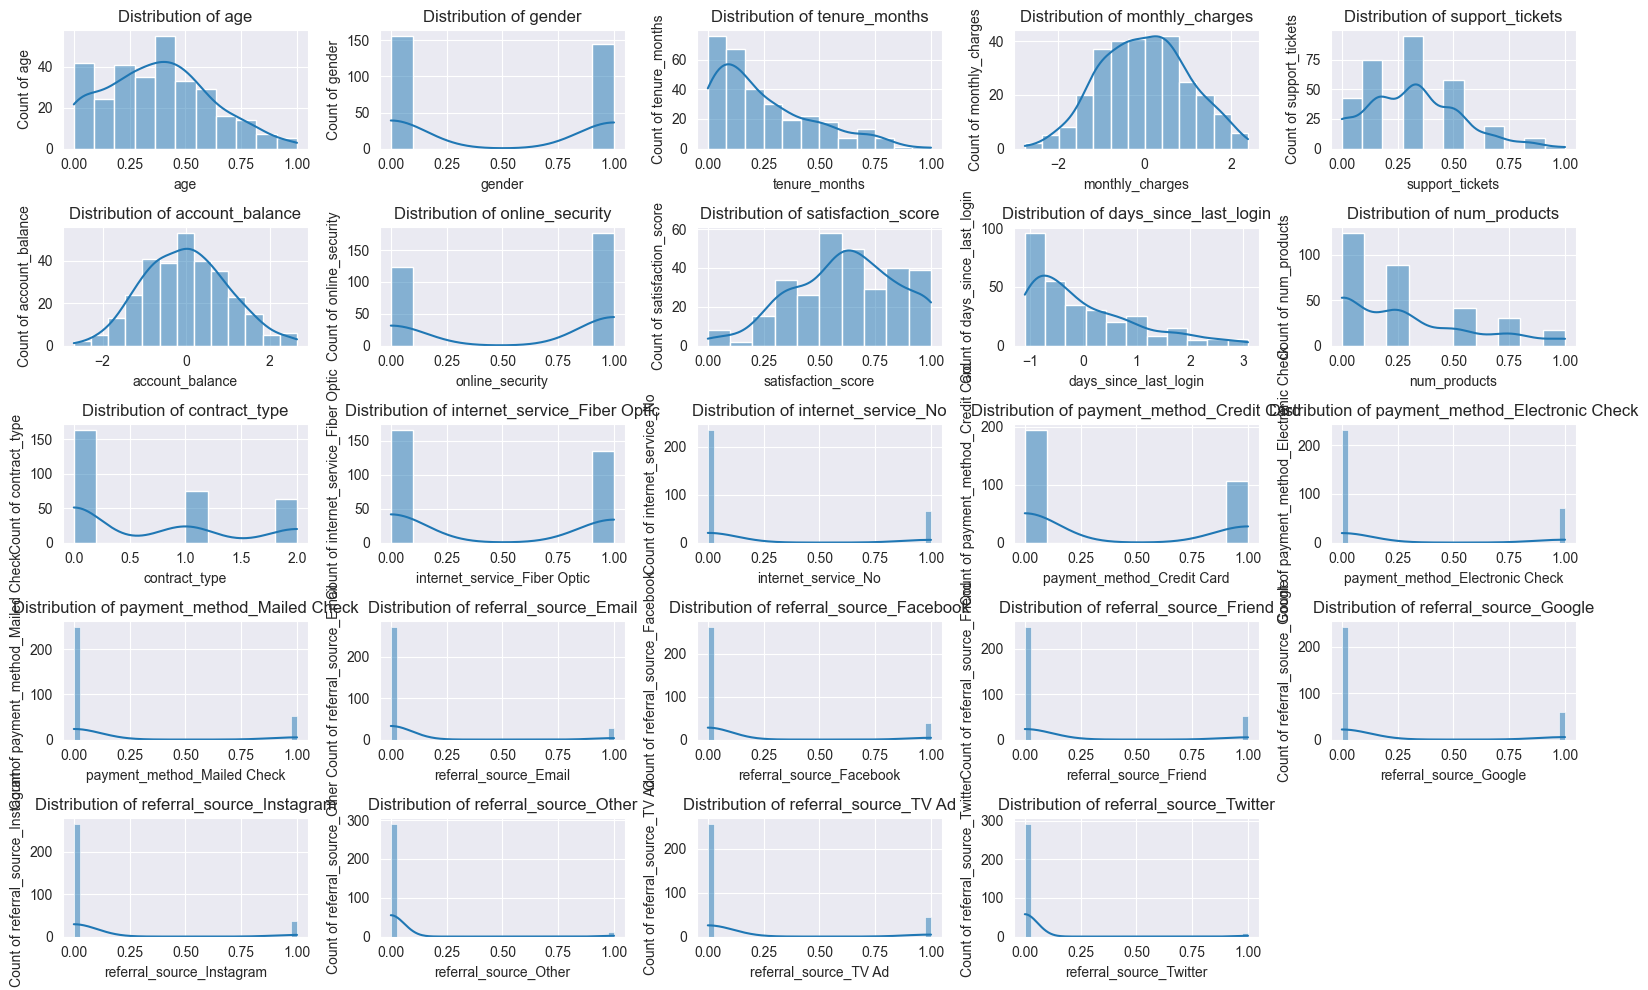

In [32]:
# Check distribution after scaling
plot_dynamic_hisplots_kdeplots(df=X_train_scaled, col_series=selected_cols, ncols=5, figsize=(16, 10))

In [33]:
# Save PREPROCESSED test data (for model evaluation)
# This is what the model sees during inference
df_test_preprocessed = pd.concat([X_test_scaled.reset_index(drop=True), y_test_raw.reset_index(drop=True)], axis=1)
df_test_preprocessed.to_csv('data/test_data_5%_preprocessed.csv', index=False)
print(f"Preprocessed test data saved to: data/test_data_5%_preprocessed.csv")
print(f"Shape: {df_test_preprocessed.shape}")

Preprocessed test data saved to: data/test_data_5%_preprocessed.csv
Shape: (26, 25)


# **STAGE 4 : MODELLING AND EVALUATION**

**Note:** All models are trained on training data and evaluated on validation data. Test set remains untouched until final evaluation.

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

# Initialize baseline models
lr = LogisticRegression(random_state=42)
knn = KNeighborsClassifier()
dt = DecisionTreeClassifier(random_state=42)
rf = RandomForestClassifier(random_state=42)
gb = GradientBoostingClassifier(random_state=42)
xgb = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')

baseline_models = {
    'Logistic Regression': lr,
    'K-Nearest Neighbors': knn,
    'Decision Tree': dt,
    'Random Forest': rf,
    'Gradient Boosting': gb,
    'XGBoost': xgb
}

# Train all baseline models
print("Training baseline models...")
for name, model in baseline_models.items():
    model.fit(X_train_scaled, y_train_clean)
    print(f"✓ {name} trained")
print("\nAll baseline models trained successfully!")

Training baseline models...
✓ Logistic Regression trained
✓ K-Nearest Neighbors trained
✓ Decision Tree trained
✓ Random Forest trained
✓ Gradient Boosting trained
✓ XGBoost trained

All baseline models trained successfully!


## Evaluation Metrics Explanation

For our **customer churn prediction** task, understanding these metrics is crucial:
 
### **Accuracy**

The proportion of correctly predicted customers (both churned and retained). While intuitive, accuracy can be misleading with imbalanced data—if only 20% of customers churn, predicting "no churn" for everyone gives 80% accuracy but misses all at-risk customers.

### **Precision**

Of all customers we predict will churn, what percentage actually churns? High precision means fewer false alarms (customers flagged as at-risk who weren't going to leave). Our target: **≥ 60%** to avoid wasting retention resources on customers who would have stayed anyway.

### **Recall (Sensitivity)**

Of all customers who actually churned, what percentage did we correctly identify? **This is our PRIMARY metric.** Missing a churning customer (false negative) is costly—they leave without intervention. Our target: **≥ 80%** to catch most at-risk customers before they leave.

### **F1 Score**

The harmonic mean of Precision and Recall, providing a balanced measure when both matter. Useful when we need to balance catching churners (recall) with not overwhelming the retention team with false alarms (precision).

### **ROC-AUC (Area Under the ROC Curve)**

Measures the model's ability to distinguish between churners and non-churners across all probability thresholds. A score of 0.5 means random guessing; 1.0 means perfect separation. Useful for comparing models and understanding overall discriminative power.

---

**For our churn prevention goal:** We prioritize **Recall** to minimize missed at-risk customers, while maintaining acceptable **Precision** to ensure retention efforts are cost-effective.


Evaluating: Logistic Regression
Performance Metrics for LogisticRegression:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  56.03 ± 4.88
  Train: 67.69 ± 1.52

PRECISION:
  Test:  47.34 ± 8.11
  Train: 65.45 ± 2.26

RECALL:
  Test:  34.87 ± 7.14
  Train: 49.68 ± 3.16

F1:
  Test:  39.94 ± 6.99
  Train: 56.43 ± 2.48

ROC_AUC:
  Test:  58.05 ± 8.14
  Train: 73.72 ± 1.73

Single Run Metrics:

ACCURACY:
  Test:  57.14
  Train: 65.78

PRECISION:
  Test:  51.61
  Train: 62.50

RECALL:
  Test:  40.00
  Train: 47.24

F1:
  Test:  45.07
  Train: 53.81

ROC_AUC:
  Test:  60.59
  Train: 72.38


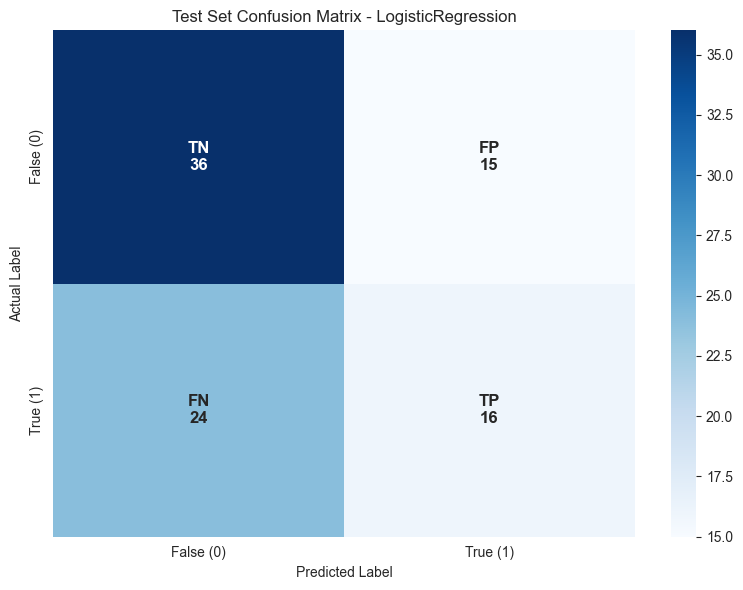

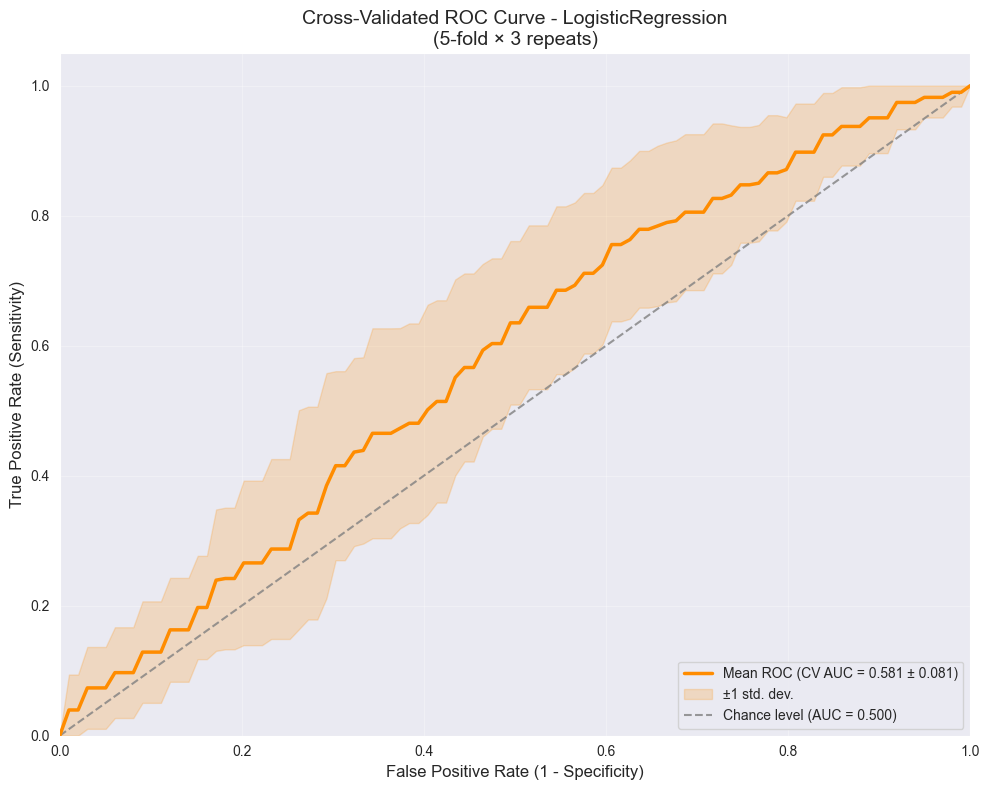


Evaluating: K-Nearest Neighbors
Performance Metrics for KNeighborsClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  50.59 ± 6.43
  Train: 70.04 ± 2.61

PRECISION:
  Test:  40.51 ± 9.27
  Train: 67.67 ± 3.43

RECALL:
  Test:  35.43 ± 8.00
  Train: 55.44 ± 4.91

F1:
  Test:  37.60 ± 8.01
  Train: 60.88 ± 4.03

ROC_AUC:
  Test:  46.78 ± 6.22
  Train: 72.59 ± 2.65

Single Run Metrics:

ACCURACY:
  Test:  53.85
  Train: 69.44

PRECISION:
  Test:  46.88
  Train: 66.06

RECALL:
  Test:  37.50
  Train: 56.69

F1:
  Test:  41.67
  Train: 61.02

ROC_AUC:
  Test:  50.61
  Train: 70.74


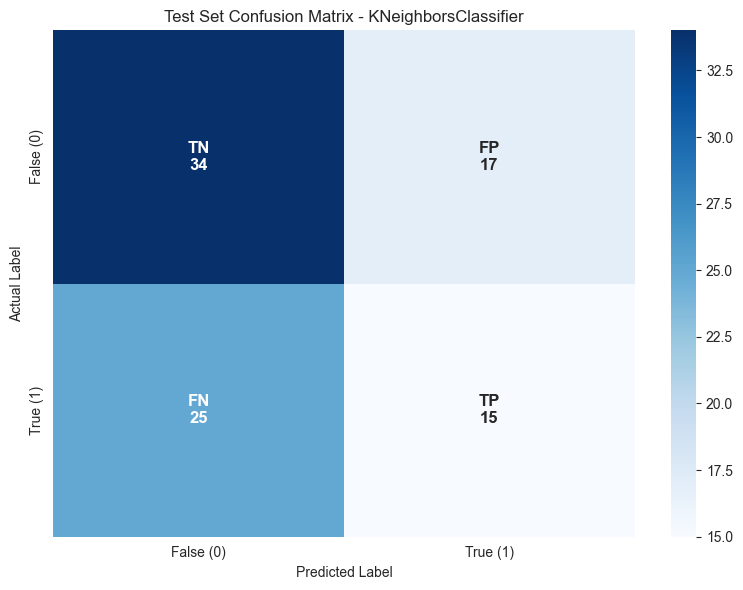

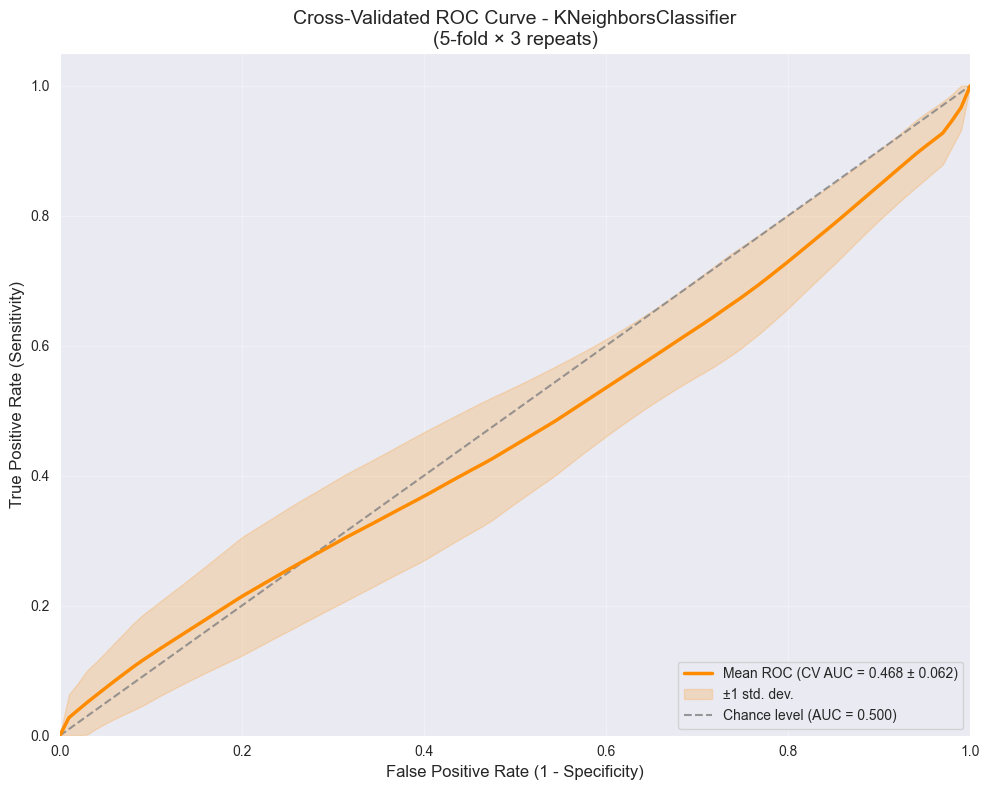


Evaluating: Decision Tree
Performance Metrics for DecisionTreeClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  50.37 ± 6.20
  Train: 100.00 ± 0.00

PRECISION:
  Test:  42.15 ± 6.57
  Train: 100.00 ± 0.00

RECALL:
  Test:  47.22 ± 8.85
  Train: 100.00 ± 0.00

F1:
  Test:  44.38 ± 7.29
  Train: 100.00 ± 0.00

ROC_AUC:
  Test:  49.94 ± 6.17
  Train: 100.00 ± 0.00

Single Run Metrics:

ACCURACY:
  Test:  50.55
  Train: 100.00

PRECISION:
  Test:  43.24
  Train: 100.00

RECALL:
  Test:  40.00
  Train: 100.00

F1:
  Test:  41.56
  Train: 100.00

ROC_AUC:
  Test:  49.41
  Train: 100.00


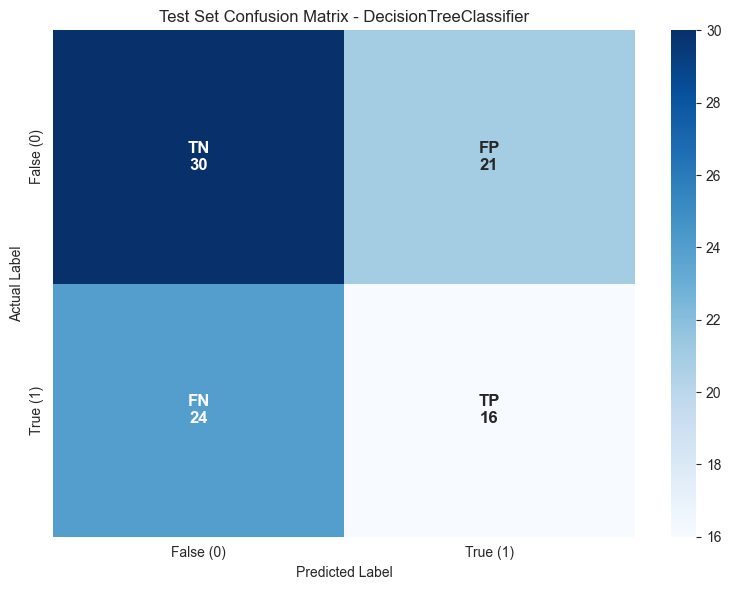

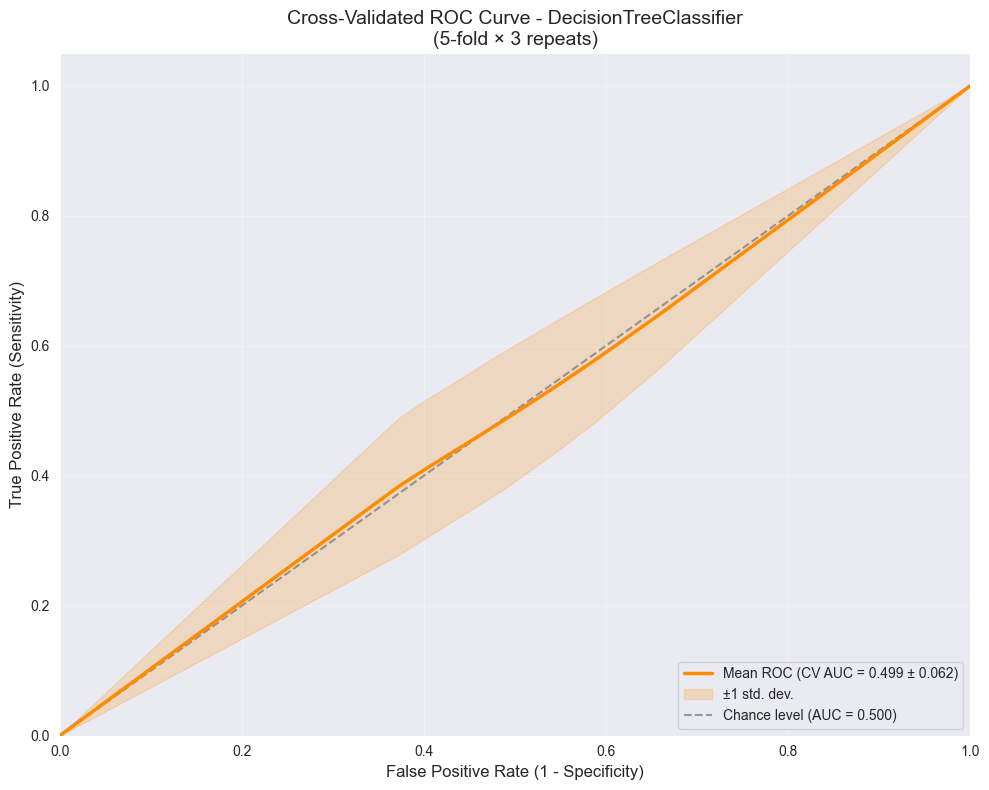


Evaluating: Random Forest
Performance Metrics for RandomForestClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  58.90 ± 4.88
  Train: 100.00 ± 0.00

PRECISION:
  Test:  52.52 ± 8.74
  Train: 100.00 ± 0.00

RECALL:
  Test:  36.98 ± 5.55
  Train: 100.00 ± 0.00

F1:
  Test:  43.17 ± 5.70
  Train: 100.00 ± 0.00

ROC_AUC:
  Test:  59.25 ± 6.95
  Train: 100.00 ± 0.00

Single Run Metrics:

ACCURACY:
  Test:  60.44
  Train: 100.00

PRECISION:
  Test:  58.33
  Train: 100.00

RECALL:
  Test:  35.00
  Train: 100.00

F1:
  Test:  43.75
  Train: 100.00

ROC_AUC:
  Test:  70.10
  Train: 100.00


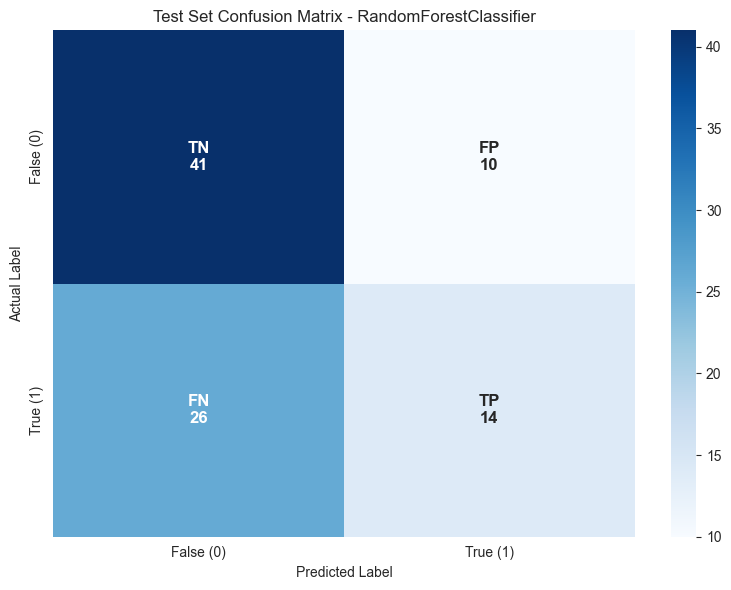

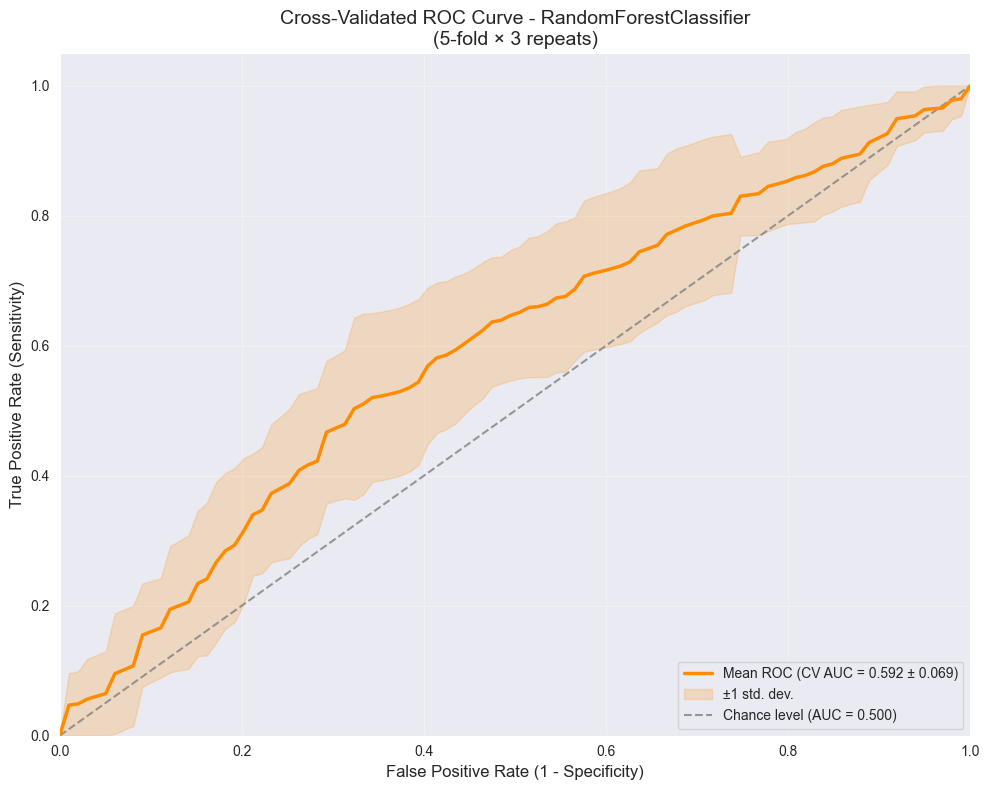


Evaluating: Gradient Boosting
Performance Metrics for GradientBoostingClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  57.15 ± 6.15
  Train: 98.98 ± 0.73

PRECISION:
  Test:  49.59 ± 7.36
  Train: 99.47 ± 0.62

RECALL:
  Test:  45.68 ± 7.26
  Train: 98.10 ± 1.27

F1:
  Test:  47.34 ± 6.61
  Train: 98.78 ± 0.87

ROC_AUC:
  Test:  57.67 ± 6.99
  Train: 99.94 ± 0.04

Single Run Metrics:

ACCURACY:
  Test:  53.85
  Train: 98.01

PRECISION:
  Test:  46.88
  Train: 98.40

RECALL:
  Test:  37.50
  Train: 96.85

F1:
  Test:  41.67
  Train: 97.62

ROC_AUC:
  Test:  57.99
  Train: 99.89


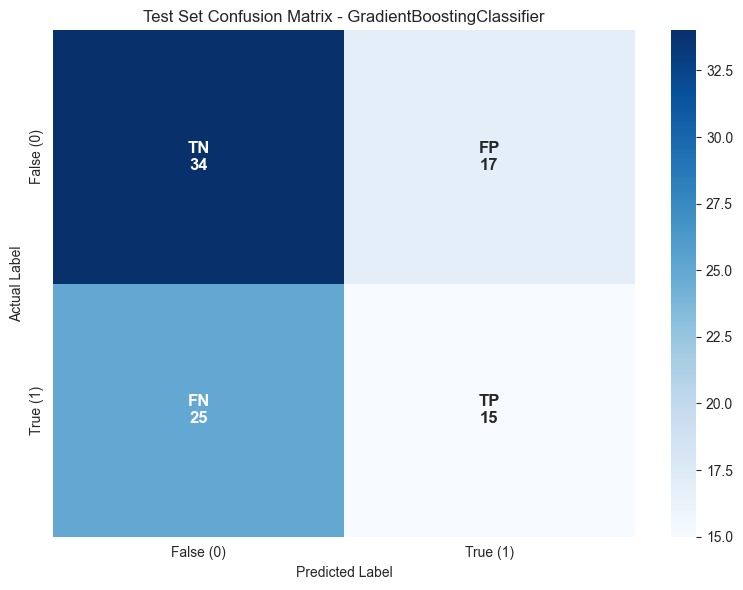

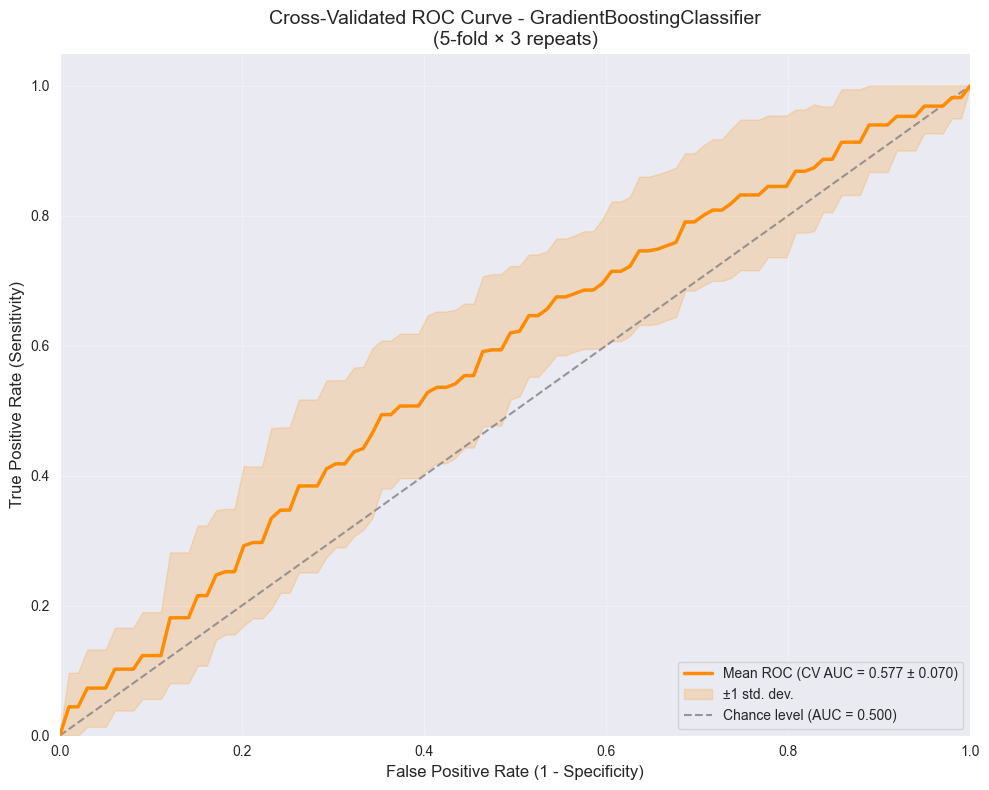


Evaluating: XGBoost
Performance Metrics for XGBClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  56.25 ± 6.12
  Train: 100.00 ± 0.00

PRECISION:
  Test:  48.35 ± 7.47
  Train: 100.00 ± 0.00

RECALL:
  Test:  45.69 ± 8.37
  Train: 100.00 ± 0.00

F1:
  Test:  46.74 ± 7.23
  Train: 100.00 ± 0.00

ROC_AUC:
  Test:  56.47 ± 7.33
  Train: 100.00 ± 0.00

Single Run Metrics:

ACCURACY:
  Test:  68.13
  Train: 100.00

PRECISION:
  Test:  67.74
  Train: 100.00

RECALL:
  Test:  52.50
  Train: 100.00

F1:
  Test:  59.15
  Train: 100.00

ROC_AUC:
  Test:  69.12
  Train: 100.00


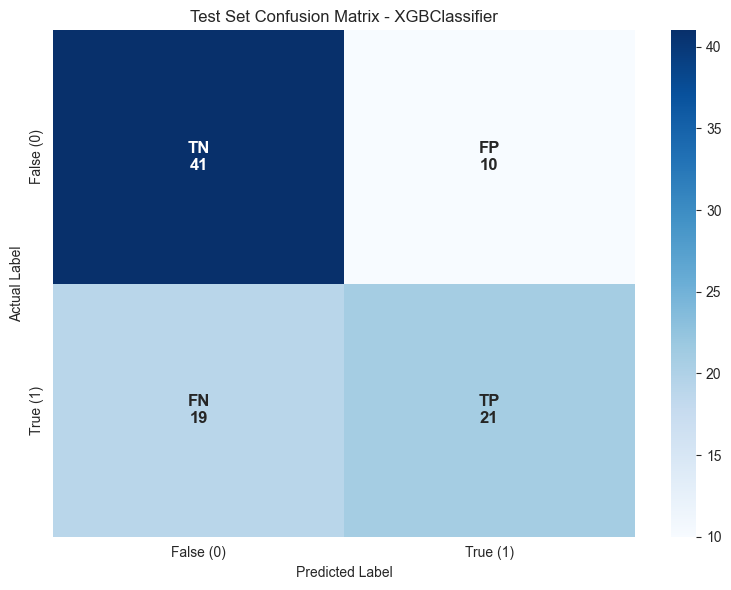

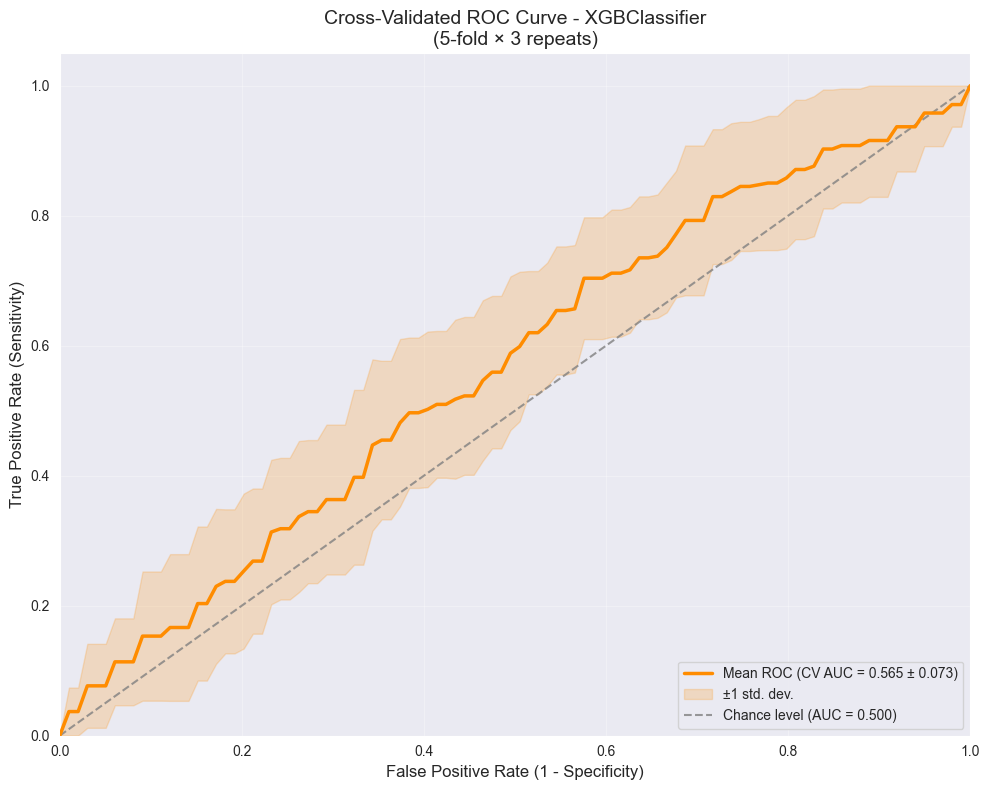

In [35]:
# Import classification evaluation and tuning utilities
from utils import eval_classification

# Evaluate each baseline model on validation set
baseline_metrics = {}

for name, model in baseline_models.items():
    print(f"\n{'='*60}")
    print(f"Evaluating: {name}")
    print('='*60)
    
    metrics = eval_classification(
        model=model,
        X_train=X_train_scaled,
        y_train=y_train_clean,
        X_test=X_val_scaled,
        y_test=y_val_clean,
        plot_confusion_matrix=True,
        plot_roc_curve=True,
        plot_pr_curve=False,
        plot_calibration_curve=False,
        plot_threshold_analysis=False,
    )
    
    baseline_metrics[name] = metrics

In [36]:
# Compare all baseline models
from utils import compare_cv_metrics_classification

comparison_df = compare_cv_metrics_classification(baseline_metrics)
print("\n=== BASELINE MODEL COMPARISON (Cross-Validation) ===\n")
comparison_df


=== BASELINE MODEL COMPARISON (Cross-Validation) ===



,Model,ACCURACY,PRECISION,RECALL,F1,ROC_AUC
0,Logistic Regression,56.03% ± 4.88%,47.34% ± 8.11%,34.87% ± 7.14%,39.94% ± 6.99%,58.05% ± 8.14%
1,K-Nearest Neighbors,50.59% ± 6.43%,40.51% ± 9.27%,35.43% ± 8.00%,37.60% ± 8.01%,46.78% ± 6.22%
2,Decision Tree,50.37% ± 6.20%,42.15% ± 6.57%,47.22% ± 8.85%,44.38% ± 7.29%,49.94% ± 6.17%
3,Random Forest,58.90% ± 4.88%,52.52% ± 8.74%,36.98% ± 5.55%,43.17% ± 5.70%,59.25% ± 6.95%
4,Gradient Boosting,57.15% ± 6.15%,49.59% ± 7.36%,45.68% ± 7.26%,47.34% ± 6.61%,57.67% ± 6.99%
5,XGBoost,56.25% ± 6.12%,48.35% ± 7.47%,45.69% ± 8.37%,46.74% ± 7.23%,56.47% ± 7.33%


In [37]:
# Find the best model for each metric
metrics_list = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
best_models = {}

for metric in metrics_list:
    best_score = 0
    best_name = None
    
    for name, metrics in baseline_metrics.items():
        if 'cv' in metrics and metric in metrics['cv']:
            score = metrics['cv'][metric]['test_mean']
            if score > best_score:
                best_score = score
                best_name = name
    
    best_models[metric] = {'model_name': best_name, 'score': best_score}

# Calculate average score across all metrics for each model (best overall)
model_avg_scores = {}
for name, metrics in baseline_metrics.items():
    if 'cv' in metrics:
        scores = []
        for metric in metrics_list:
            if metric in metrics['cv']:
                scores.append(metrics['cv'][metric]['test_mean'])
        if scores:
            model_avg_scores[name] = sum(scores) / len(scores)

# Find best overall model
best_overall_name = max(model_avg_scores, key=model_avg_scores.get)
best_overall_avg = model_avg_scores[best_overall_name]

print("=== Best Model for Each Metric ===\n")
for metric, info in best_models.items():
    print(f"★ {metric.upper():12s}: {info['model_name']} ({info['score']*100:.2f}%)")

print("\n=== Average Scores Across All Metrics ===\n")
for name, avg_score in sorted(model_avg_scores.items(), key=lambda x: x[1], reverse=True):
    marker = "★" if name == best_overall_name else " "
    print(f"{marker} {name:25s}: {avg_score*100:.2f}%")

print(f"\n→ Best Overall Model: {best_overall_name} (avg = {best_overall_avg*100:.2f}%)")

=== Best Model for Each Metric ===

★ ACCURACY    : Random Forest (58.90%)
★ PRECISION   : Random Forest (52.52%)
★ RECALL      : Decision Tree (47.22%)
★ F1          : Gradient Boosting (47.34%)
★ ROC_AUC     : Random Forest (59.25%)

=== Average Scores Across All Metrics ===

★ Gradient Boosting        : 51.49%
  XGBoost                  : 50.70%
  Random Forest            : 50.16%
  Logistic Regression      : 47.25%
  Decision Tree            : 46.81%
  K-Nearest Neighbors      : 42.18%

→ Best Overall Model: Gradient Boosting (avg = 51.49%)


Tuning Random Forest...


Processing Pipelines:   0%|          | 0/1 [00:00<?, ?it/s]


Validation curve for rf__n_estimators...
  rf__n_estimators=50: train=1.000, test=0.350
  rf__n_estimators=100: train=1.000, test=0.350
  rf__n_estimators=200: train=1.000, test=0.400


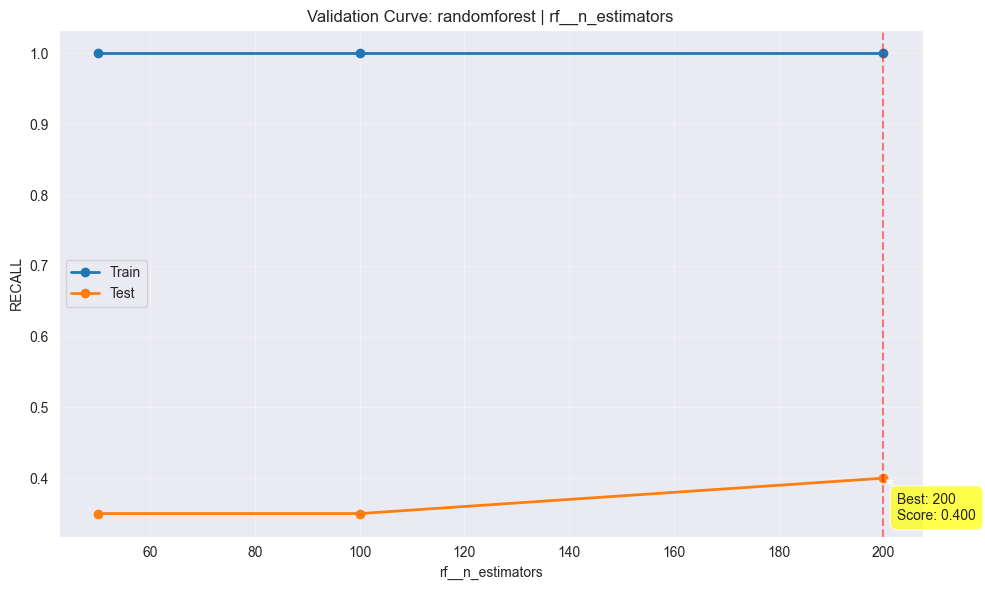


Validation curve for rf__criterion...
  rf__criterion=entropy: train=1.000, test=0.400
  rf__criterion=gini: train=1.000, test=0.350


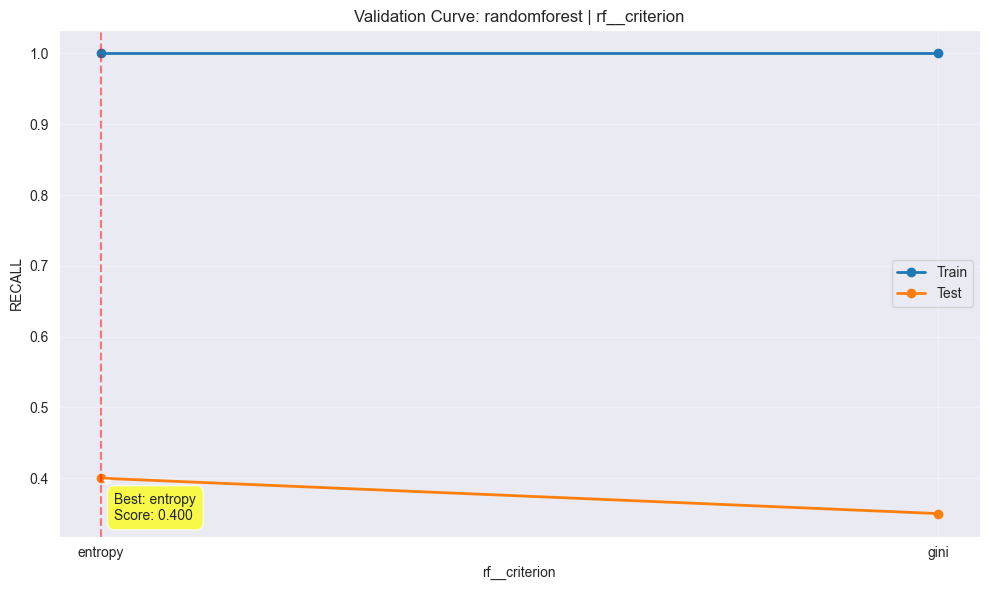


Validation curve for rf__max_depth...
  rf__max_depth=5: train=0.724, test=0.300
  rf__max_depth=10: train=1.000, test=0.400
  rf__max_depth=15: train=1.000, test=0.350
  rf__max_depth=20: train=1.000, test=0.350


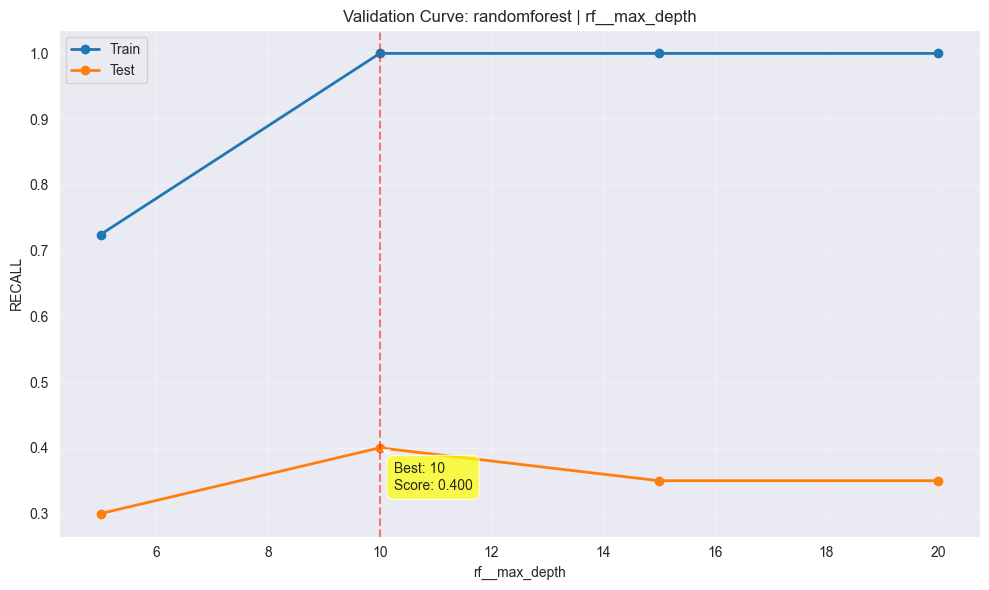


Validation curve for rf__min_samples_split...
  rf__min_samples_split=2: train=1.000, test=0.350
  rf__min_samples_split=5: train=0.992, test=0.325
  rf__min_samples_split=10: train=0.929, test=0.350


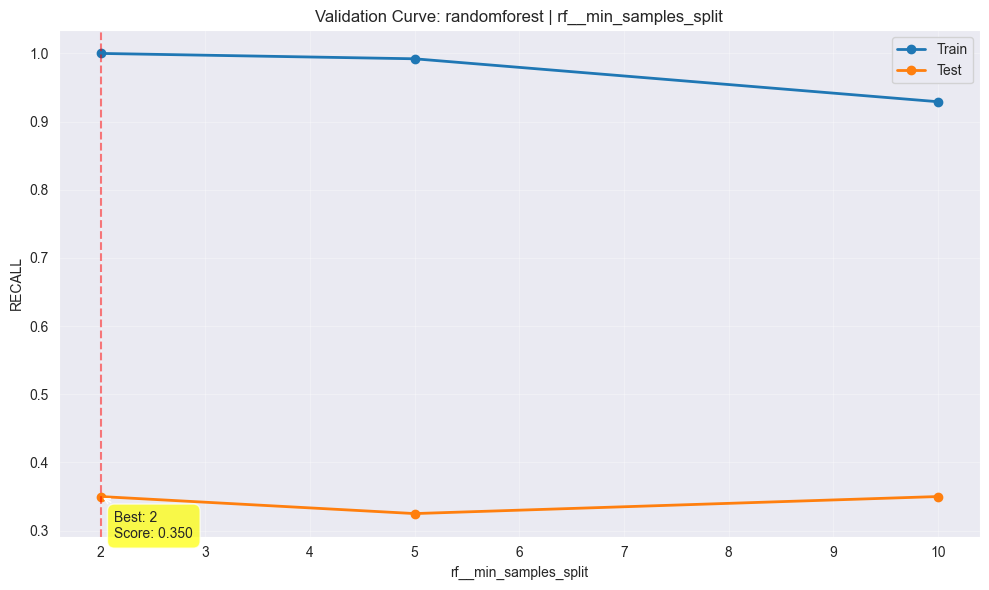


Validation curve for rf__max_features...
  rf__max_features=sqrt: train=1.000, test=0.350
  rf__max_features=log2: train=1.000, test=0.350


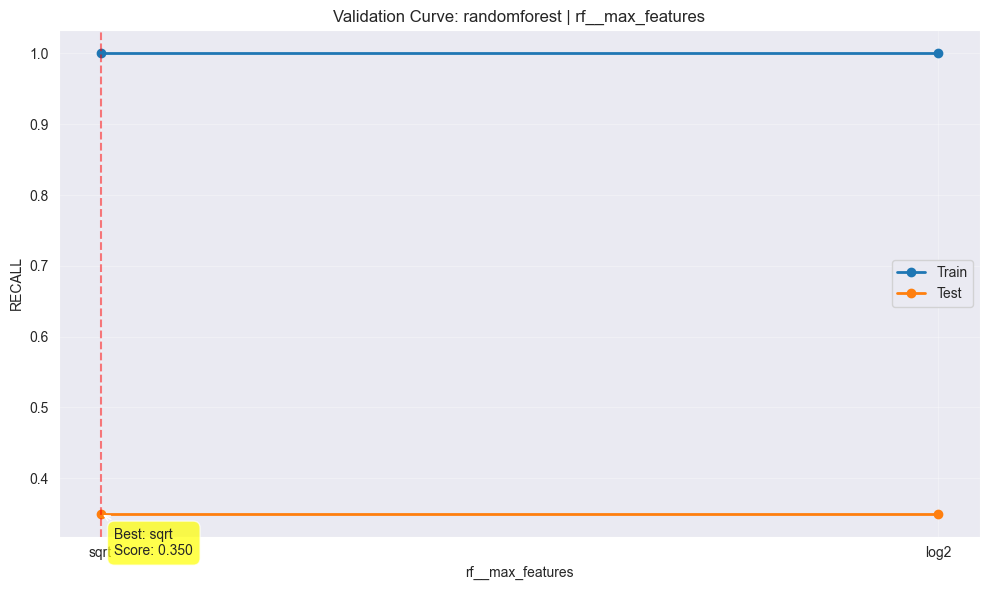


Validation curve for rf__min_samples_leaf...
  rf__min_samples_leaf=1: train=1.000, test=0.350
  rf__min_samples_leaf=2: train=0.992, test=0.275
  rf__min_samples_leaf=4: train=0.850, test=0.325


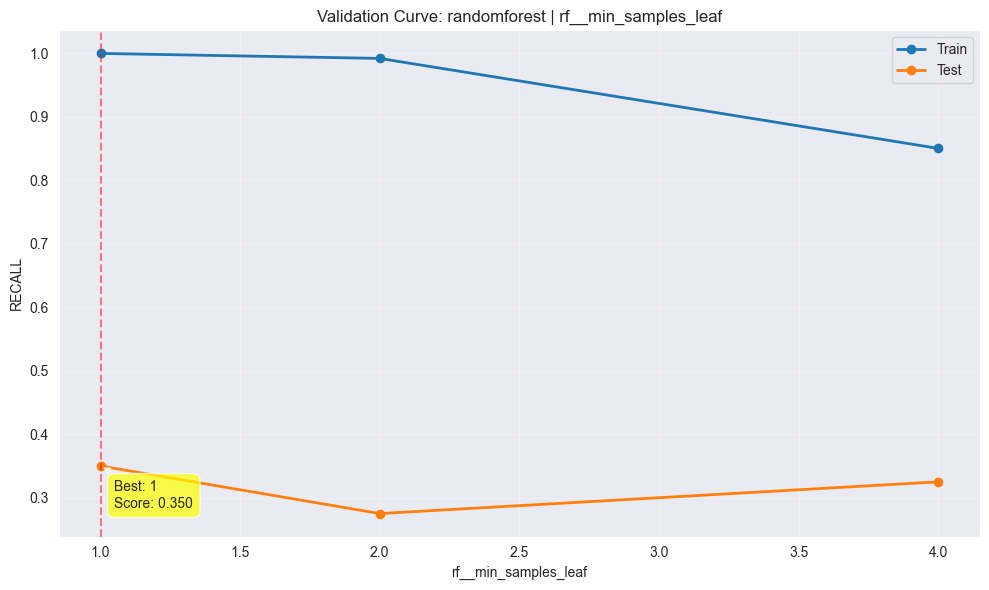

Validation Curves for randomforest: 100%|██████████| 6/6 [00:04<00:00,  1.44it/s]


Fitting 15 folds for each of 432 candidates, totalling 6480 fits

Results for randomforest (GRID Search)
Fit Time: 289.85s
Best CV recall: 0.4040

Best Parameters:
  rf__criterion: gini
  rf__max_depth: 10
  rf__max_features: sqrt
  rf__min_samples_leaf: 4
  rf__min_samples_split: 10
  rf__n_estimators: 50

Test recall: 0.3000

Generating learning curves for randomforest...


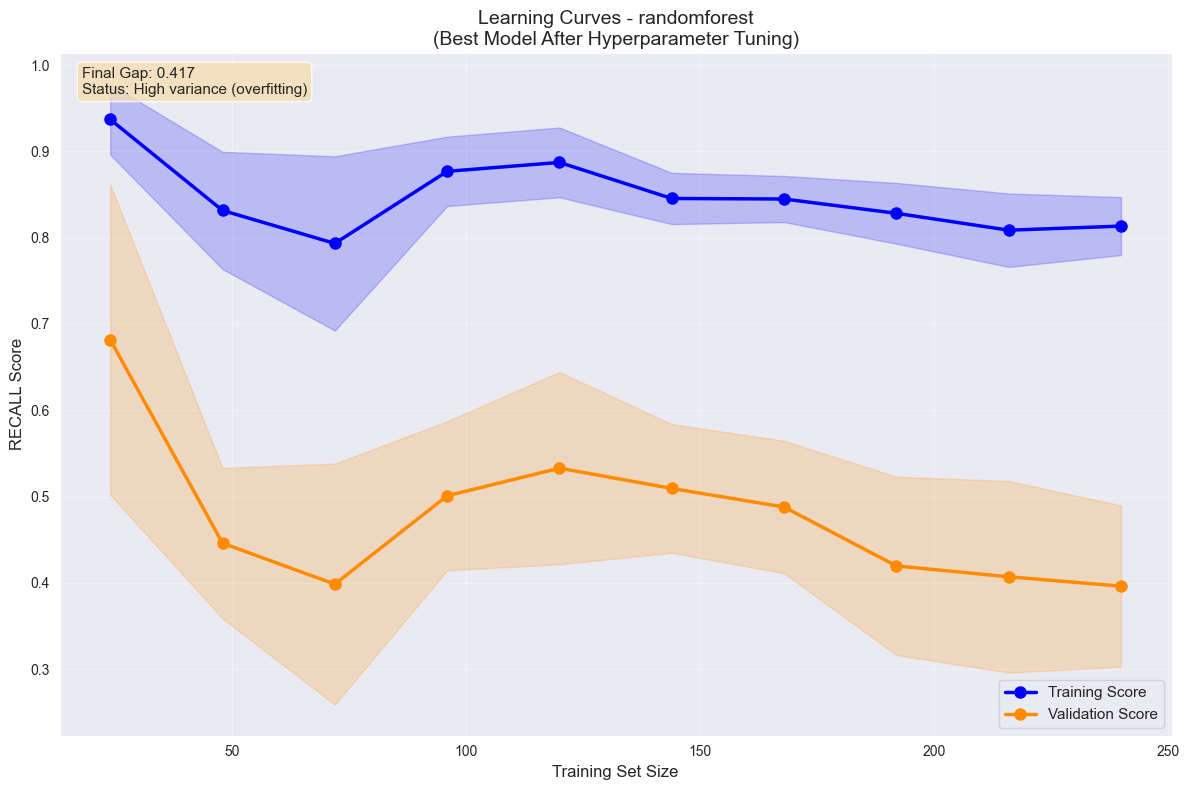

Processing Pipelines: 100%|██████████| 1/1 [04:57<00:00, 297.22s/it]


✓ Tuning complete!
Best CV Score: 0.4040
Best Parameters: {'rf__criterion': 'gini', 'rf__max_depth': 10, 'rf__max_features': 'sqrt', 'rf__min_samples_leaf': 4, 'rf__min_samples_split': 10, 'rf__n_estimators': 50}


In [38]:
# Hyperparameter tuning for best model
from utils import tune_single_model_classification

best_model_name = "Random Forest" # the method to extract this can be from previous code cell instead of hard-coded
model_key_map = {
    'Logistic Regression': 'logisticregression',
    'K-Nearest Neighbors': 'knn',
    'Decision Tree': 'decisiontree',
    'Random Forest': 'randomforest',
    'Gradient Boosting': 'gb',
    'XGBoost': 'xgboost',
}

best_model_key = model_key_map[best_model_name]

print(f"Tuning {best_model_name}...")

rf_tuned, fit_time = tune_single_model_classification(
    model_name=best_model_key,
    X_train=X_train_scaled,
    y_train=y_train_clean,
    X_test=X_val_scaled,
    y_test=y_val_clean,
    search_method='grid',
    scoring='recall',
    display=True,
    progress_bar=True,
    plot_validation_curves=True,
    plot_learning_curves=True
)

print(f"\n✓ Tuning complete!")
print(f'Best CV Score: {rf_tuned.best_score_:.4f}')
print(f'Best Parameters: {rf_tuned.best_params_}')

In [34]:
# Train final model with tuned hyperparameters (optional for direct run without running the whole notebook)
from sklearn.ensemble import RandomForestClassifier

rf_tuned_direct = RandomForestClassifier(
    random_state=42,
    n_estimators=50,
    criterion='gini',
    max_depth=10, 
    max_features='sqrt', 
    min_samples_leaf=4, 
    min_samples_split=10, 
)
rf_tuned_direct.fit(X_train_scaled, y_train_clean)

,n_estimators,50
,criterion,'gini'
,max_depth,10
,min_samples_split,10
,min_samples_leaf,4
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


Performance Metrics for RandomForestClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  60.46 ± 6.02
  Train: 89.98 ± 2.01

PRECISION:
  Test:  55.04 ± 8.67
  Train: 95.27 ± 1.99

RECALL:
  Test:  40.40 ± 7.13
  Train: 80.24 ± 4.47

F1:
  Test:  46.25 ± 7.00
  Train: 87.04 ± 2.85

ROC_AUC:
  Test:  60.64 ± 7.27
  Train: 97.71 ± 0.63

Single Run Metrics:

ACCURACY:
  Test:  61.54
  Train: 88.37

PRECISION:
  Test:  63.16
  Train: 94.23

RECALL:
  Test:  30.00
  Train: 77.17

F1:
  Test:  40.68
  Train: 84.85

ROC_AUC:
  Test:  66.96
  Train: 97.04


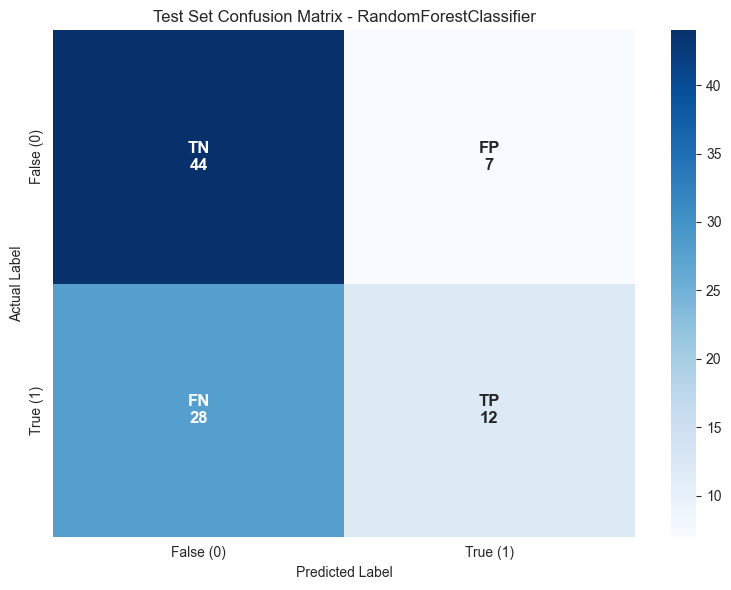

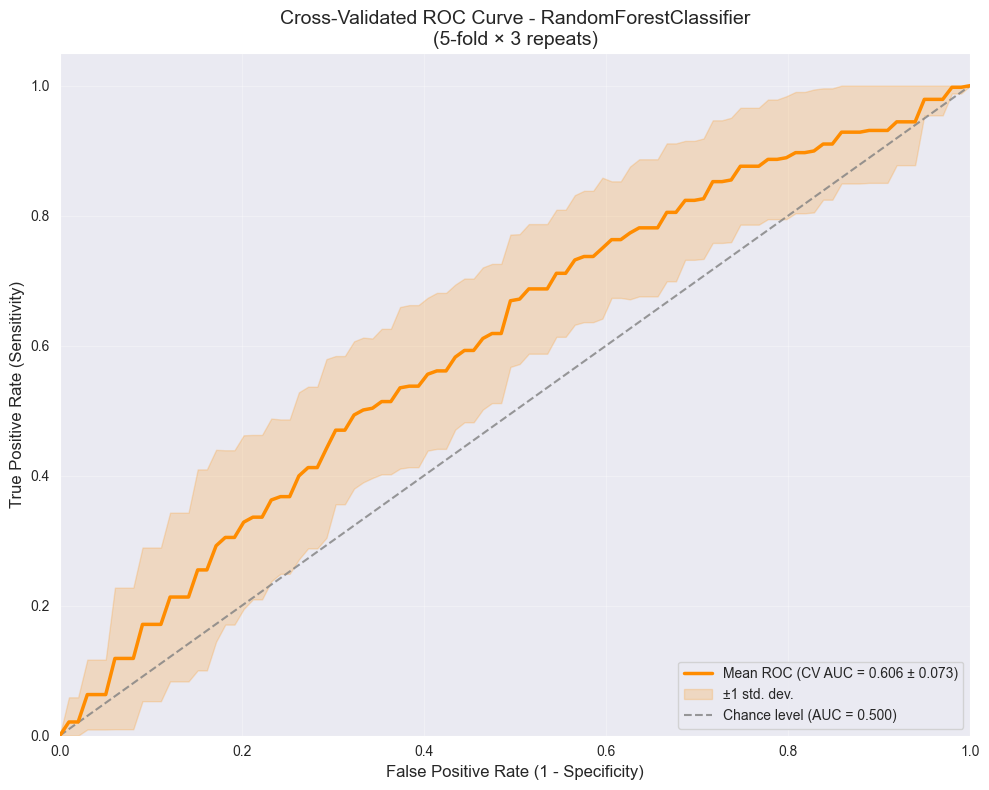

In [37]:
# Evaluate tuned model
from utils import eval_classification

tuned_metrics = eval_classification(
    model=rf_tuned_direct,
    X_train=X_train_scaled,
    y_train=y_train_clean,
    X_test=X_val_scaled,
    y_test=y_val_clean,
    plot_confusion_matrix=True,
    plot_roc_curve=True,
    plot_pr_curve=False,
    plot_calibration_curve=False,
    plot_threshold_analysis=False,
)

# **STAGE 5 : Business Impact Simulation**

In [38]:
# Business Impact Analysis
from sklearn.metrics import confusion_matrix

# Get predictions
y_val_pred = rf_tuned_direct.predict(X_val_scaled)
tn, fp, fn, tp = confusion_matrix(y_val_clean, y_val_pred).ravel()

# Business parameters
avg_customer_value = 1000  # $ per year
retention_cost = 100  # $ per customer
retention_success_rate = 0.70

print("="*60)
print("CONFUSION MATRIX")
print("="*60)
print(f"TP: {tp} | FN: {fn}")
print(f"FP: {fp} | TN: {tn}")

# Calculate business impact
customers_intervened = tp + fp
retained = tp * retention_success_rate
retention_cost_total = customers_intervened * retention_cost
revenue_saved = retained * avg_customer_value
net_benefit = revenue_saved - retention_cost_total

roi = (net_benefit / retention_cost_total * 100) if retention_cost_total > 0 else 0

print("\n" + "="*60)
print("BUSINESS IMPACT")
print("="*60)
print(f"Customers Targeted: {customers_intervened}")
print(f"Successfully Retained: {retained:.0f}")
print(f"Retention Cost: ${retention_cost_total:,.0f}")
print(f"Revenue Saved: ${revenue_saved:,.0f}")
print(f"Net Benefit: ${net_benefit:,.0f}")
print(f"ROI: {roi:.1f}%")

# Project to full customer base
total_customers = 10000
scale = total_customers / len(y_val_clean)
print(f"\nProjected Annual Impact ({total_customers:,} customers):")
print(f"  Net Benefit: ${net_benefit * scale:,.0f}")
print("="*60)

CONFUSION MATRIX
TP: 12 | FN: 28
FP: 7 | TN: 44

BUSINESS IMPACT
Customers Targeted: 19
Successfully Retained: 8
Retention Cost: $1,900
Revenue Saved: $8,400
Net Benefit: $6,500
ROI: 342.1%

Projected Annual Impact (10,000 customers):
  Net Benefit: $714,286


# **STAGE 6: FINAL TEST SET EVALUATION**

**Purpose:** Get unbiased estimate of model performance on truly unseen data.

FINAL TEST SET EVALUATION
Performance Metrics for RandomForestClassifier:

Cross-Validated Metrics (mean ± std):

ACCURACY:
  Test:  60.46 ± 6.02
  Train: 89.98 ± 2.01

PRECISION:
  Test:  55.04 ± 8.67
  Train: 95.27 ± 1.99

RECALL:
  Test:  40.40 ± 7.13
  Train: 80.24 ± 4.47

F1:
  Test:  46.25 ± 7.00
  Train: 87.04 ± 2.85

ROC_AUC:
  Test:  60.64 ± 7.27
  Train: 97.71 ± 0.63

Single Run Metrics:

ACCURACY:
  Test:  69.23
  Train: 88.37

PRECISION:
  Test:  75.00
  Train: 94.23

RECALL:
  Test:  30.00
  Train: 77.17

F1:
  Test:  42.86
  Train: 84.85

ROC_AUC:
  Test:  73.12
  Train: 97.04


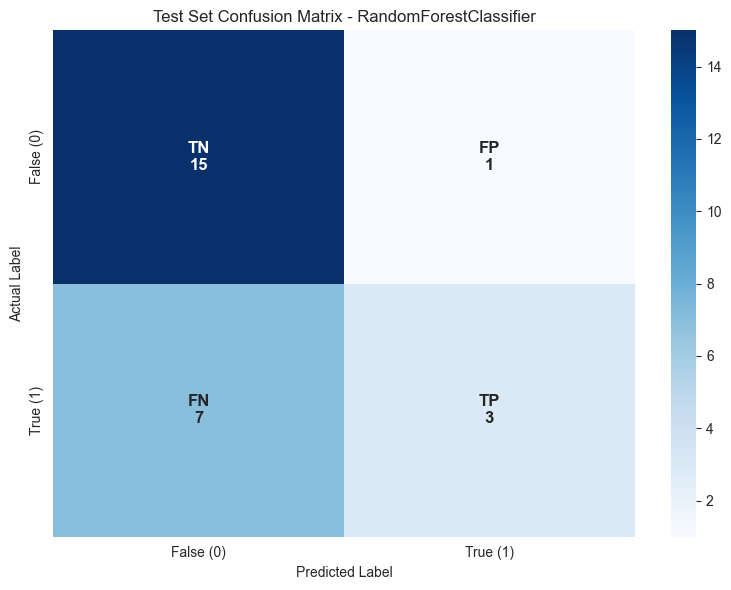

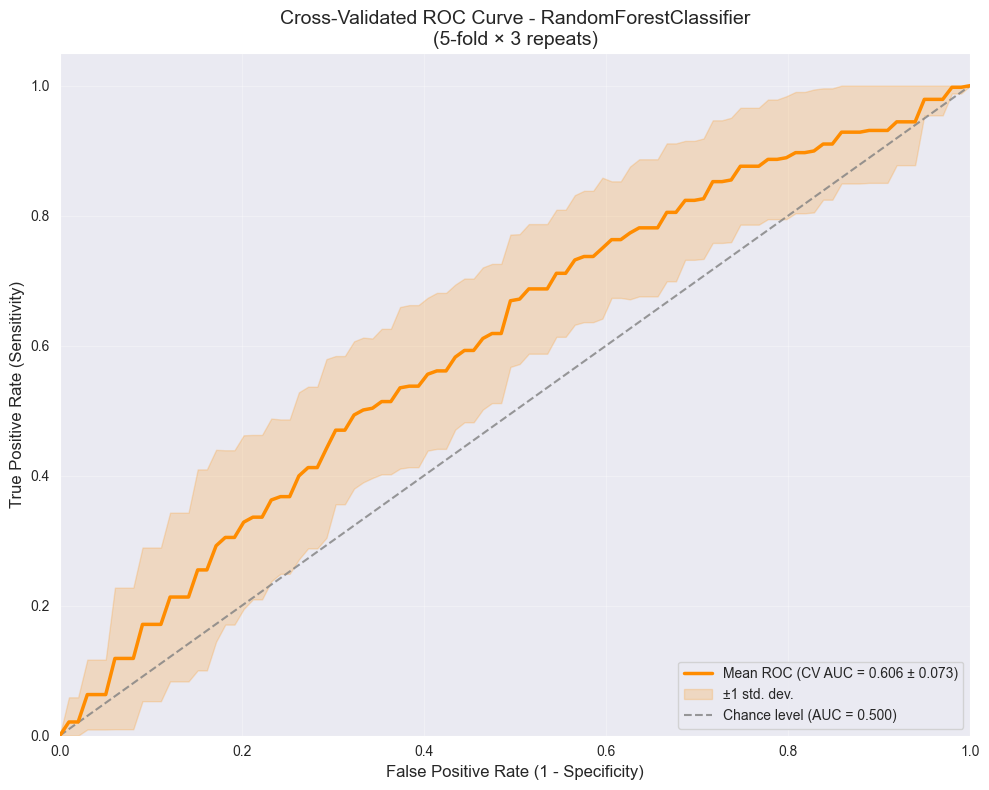


These are the final, unbiased performance metrics.


In [39]:
# Final evaluation on TEST set
print("=" * 60)
print("FINAL TEST SET EVALUATION")
print("=" * 60)

metrics_test = eval_classification(
    model=rf_tuned_direct,
    X_train=X_train_scaled,
    y_train=y_train_clean,
    X_test=X_test_scaled,
    y_test=y_test_raw,
    plot_confusion_matrix=True,
    plot_roc_curve=True,
    plot_pr_curve=False,
    plot_calibration_curve=False,
    plot_threshold_analysis=False,
)

print("\n" + "=" * 60)
print("These are the final, unbiased performance metrics.")
print("=" * 60)